 ### 0.4 Experimental Configuration

We define a comprehensive configuration dictionary that encapsulates all model hyperparameters, training settings, and forecasting modes. This approach follows best practices for:
- **Experiment tracking:** All settings in one place
- **Reproducibility:** Easy to save/load configurations
- **Hyperparameter tuning:** Clear parameter organization

**Key Design Decisions:**

| Parameter | Value | Justification | Reference |
|-----------|-------|---------------|-----------|
| `lookback_hours` | 168 (7 days) | Captures weekly patterns | Wang et al. (2019) |
| `lstm_units` | 128 → 64 | Decreasing bottleneck | Abdel-Nasser (2019) |
| `attention_heads` | 4 | Multi-pattern learning | Lim et al. (2021) |
| `dropout_rate` | 0.2 | Prevents overfitting | Consensus |
| `batch_size` | 64 | GPU memory vs stability | Empirical |
| `learning_rate` | 0.001 | Adam optimizer default | Kingma & Ba (2015) |

---

## Forecasting Strategy: Direct vs. Indirect

### Mathematical Formulation

#### Direct Forecasting:
Predict power output $P_t$ directly from input features $X_{t-168:t}$:

$$
\hat{P}_t = f_{\text{LSTM}}(X_{t-168:t}; \theta_{\text{direct}})
$$

where $\theta_{\text{direct}}$ are the learned parameters.

**Advantages:**
- End-to-end learning optimizes directly for target metric
- No dependency on intermediate theoretical models
- Literature: 1-3% better RMSE (Zhang et al. 2020)

**Disadvantages:**
- Less interpretable (black-box predictions)
- Cannot enforce physical bounds easily
- Loses domain knowledge about PV systems

---

#### Indirect Forecasting:
Predict performance ratio $K_t$ (Clear Sky Index), then compute power:

$$
\hat{K}_t = f_{\text{LSTM}}(X_{t-168:t}; \theta_{\text{indirect}})
$$

$$
\hat{P}_t = \hat{K}_t \times P_{\text{theoretical},t}
$$

where:
- $K_t \in [0, 1.2]$ is the performance ratio (bounded by physics)
- $P_{\text{theoretical},t}$ is the clear-sky theoretical power

**Advantages:**
- Physically interpretable ($K$ = ratio of actual/theoretical)
- Natural bounds: $K \in [0, 1.2]$ (can clip predictions)
- Leverages domain knowledge (clear-sky model)
- Better for anomaly detection (abnormal $K$ values)

**Disadvantages:**
- Depends on accuracy of $P_{\text{theoretical}}$
- Two-step process introduces error propagation
- Literature: 1-3% worse RMSE than Direct

---

### Literature Evidence

| Study | Metric | Direct | Indirect | Winner |
|-------|--------|--------|----------|--------|
| Zhang et al. (2020) | RMSE | 187.3 kW | 192.1 kW | Direct (+2.5%) |
| Wang et al. (2019) | nRMSE | 6.2% | 6.5% | Direct (+0.3%) |
| Our XGBoost (NB06) | RMSE | 202.60 kW | 204.16 kW | Direct (+0.8%) |

**Consensus:** Direct forecasting achieves slightly better accuracy, but **ensemble of both** (weighted combination) typically outperforms either alone (Dong et al. 2020).

---

### Our Approach: Train Both + Ensemble

We implement both strategies to:

1. **Validate literature findings** in our specific context
2. **Compare performance** on identical test set
3. **Create ensemble** with optimal weighting:
   $$
   \hat{P}_{\text{ensemble}} = w \cdot \hat{P}_{\text{direct}} + (1-w) \cdot \hat{P}_{\text{indirect}}
   $$
   where $w \in [0,1]$ is optimized via grid search or learned via stacking

4. **Statistical testing** (Diebold-Mariano test) to verify significance of differences

**Expected outcome:** Ensemble achieves 2-5% RMSE improvement over best individual model (based on solar forecasting literature meta-analysis).

---

### References

1. Wang, H., et al. (2019). A comparison of day-ahead photovoltaic power forecasting models based on deep learning neural network. *Applied Energy*, 251, 113315.

2. Zhang, J., et al. (2020). Short-term forecasting and uncertainty analysis of photovoltaic power based on LSTM. *Energy*, 201, 117663.

3. Abdel-Nasser, M., & Mahmoud, K. (2019). Accurate photovoltaic power forecasting models using deep LSTM-RNN. *Neural Computing and Applications*, 31, 2727-2740.

4. Lim, B., et al. (2021). Temporal Fusion Transformers for Interpretable Multi-horizon Time Series Forecasting. *International Journal of Forecasting*, 37(4), 1748-1764.

5. Kingma, D. P., & Ba, J. (2015). Adam: A method for stochastic optimization. *ICLR*.

6. Dong, Z., et al. (2020). A review of multi-model ensemble forecasting methods for renewable energy. *Renewable and Sustainable Energy Reviews*, 133, 110184.

---

**Next:** Cell 0 - Environment verification and configuration

In [1]:
# ==============================================================================
# CELL 0: Import Libraries & Basic Configuration
# ==============================================================================
# Purpose: Load all required dependencies and set reproducibility parameters
# Expected runtime: < 5 seconds
# ==============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import json
import warnings
import sys
import os
from datetime import datetime

# Deep Learning Framework
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, callbacks, regularizers

# Scikit-learn for preprocessing and metrics
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import joblib

# Suppress warnings for cleaner output
warnings.filterwarnings('ignore')
os.environ['    TF_CPP_MIN_LOG_LEVEL'] = '2'  # Suppress TensorFlow warnings

# ==============================================================================
# REPRODUCIBILITY: Fix All Random Seeds
# ==============================================================================
# Critical for scientific reproducibility - ensures identical results across runs
# Note: GPU operations may still introduce minor (< 0.1%) numerical differences

RANDOM_SEED = 42

# NumPy random seed
np.random.seed(RANDOM_SEED)

# TensorFlow/Keras random seed
tf.random.set_seed(RANDOM_SEED)

# Python's built-in random seed
import random
random.seed(RANDOM_SEED)

# ==============================================================================
# Verify Environment
# ==============================================================================

print("=    " * 80)
print("ENVIRONMENT VERIFICATION")
print("=" * 80)

print(f"\n✅ Python Version: {sys.version.split()[0]}")
print(f"✅ NumPy Version: {np.__version__}")
print(f"✅ Pandas Version: {pd.__version__}")
print(f"✅ TensorFlow Version: {tf.__version__}")

# Check GPU availability
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f"✅ GPU Available: {len(gpus)} device(s)")
    for gpu in gpus:
        print(f"   └─ {gpu.name}")
    print(f"   Expected training time: 5-10 min per model")
else:
    print(f"⚠️  No GPU detected - using CPU")
    print(f"   Expected training time: 30-60 min per model")

print(f"\n✅ Random Seed: {RANDOM_SEED} (set for NumPy, TensorFlow, Python)")

# Matplotlib configuration for publication-quality plots
plt.style.use('seaborn-v0_8-darkgrid')
sns.    set_palette('husl')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['legend.fontsize'] = 10

print(f"✅ Matplotlib configured for publication-quality plots")

print("\n" + "=" * 80)
print("ENVIRONMENT READY")
print("=" * 80)


=    =    =    =    =    =    =    =    =    =    =    =    =    =    =    =    =    =    =    =    =    =    =    =    =    =    =    =    =    =    =    =    =    =    =    =    =    =    =    =    =    =    =    =    =    =    =    =    =    =    =    =    =    =    =    =    =    =    =    =    =    =    =    =    =    =    =    =    =    =    =    =    =    =    =    =    =    =    =    =    
ENVIRONMENT VERIFICATION

✅ Python Version: 3.10.19
✅ NumPy Version: 1.26.4
✅ Pandas Version: 2.3.3
✅ TensorFlow Version: 2.15.0
⚠️  No GPU detected - using CPU
   Expected training time: 30-60 min per model

✅ Random Seed: 42 (set for NumPy, TensorFlow, Python)
✅ Matplotlib configured for publication-quality plots

ENVIRONMENT READY


    ## Section 1: Project Configuration & Path Management

### 1.1 Directory Structure

We implement a **systematic directory organization** following software engineering best practices for reproducible research (Wilson et al. 2017):
```
solar_ds_capstone/
├── data/
│   └── features_1H_target_k.parquet         # Engineered features (from NB04)
├── artifacts/
│   └── 05_feature_selection/
│       └── final_selected_features.json      # Selected features (from NB05)
├── models/
│   └── 07_lstm/
│       ├── direct/                           # Direct forecasting models
│       │   ├── model_final.keras
│       │   ├── scaler_features.pkl
│       │   ├── scaler_target.pkl
│       │   └── config.json
│       └── indirect/                         # Indirect forecasting models
│           ├── model_final.keras
│           ├── scaler_features.pkl
│           ├── scaler_target.pkl
│           └── config.json
└── outputs/
    └── 07_lstm/
        ├── reports/                          # Metrics, comparisons
        │   ├── metrics_direct.csv
        │   ├── metrics_indirect.csv
        │   └── ensemble_results.json
        └── plots/                            # Visualizations
            ├── training_history_*.png
            ├── predictions_*.png
            └── comparison_*.png
```

**Rationale:**
- **Separation of concerns:** Raw data, models, and outputs isolated
- **Version control friendly:** Models excluded from git (large binaries)
- **Reproducibility:** Clear input/output mapping for each experiment
- **Scalability:** Easy to add new model variants

---

### 1.2 Experimental Configuration

We define a comprehensive configuration dictionary `LSTM_CONFIG` that serves as a **single source of truth** for all experimental parameters. This approach enables:

1. **Reproducibility:** Exact parameter settings preserved
2. **Experiment tracking:** Easy to save/compare configurations
3. **Hyperparameter tuning:** Structured parameter space
4. **Code clarity:** Reduces magic numbers

---

### 1.3 Hyperparameter Justification

Our hyperparameter choices are grounded in solar forecasting literature:

| Parameter | Value | Justification | Source |
|-----------|-------|---------------|--------|
| **Architecture** |
| `lookback_hours` | 168 (7 days) | Captures weekly patterns + daily cycles | Wang et al. (2019) |
| `lstm_units_1` | 128 | Sufficient capacity for temporal features | Empirical consensus |
| `lstm_units_2` | 64 | Decreasing bottleneck architecture | Abdel-Nasser (2019) |
| `dense_units` | 32 | Final feature compression | Standard practice |
| `attention_heads` | 4 | Multi-pattern learning without overfitting | Lim et al. (2021) |
| **Regularization** |
| `dropout_rate` | 0.2 | Prevents overfitting (20% dropout) | Srivastava et al. (2014) |
| `l2_reg` | 0.001 | Weight decay for generalization | Consensus |
| **Training** |
| `batch_size` | 64 | Balance: GPU memory vs gradient stability | Empirical |
| `learning_rate` | 0.001 | Adam optimizer default (stable) | Kingma & Ba (2015) |
| `epochs` | 100 | With early stopping (patience=15) | Standard |
| **Data Split** |
| `test_size` | 0.15 | 15% holdout for final evaluation | Common practice |
| `validation_split` | 0.15 | 15% of train for early stopping | Common practice |

**Final Split:** ~70% Train, ~15% Validation, ~15% Test (chronological)

---

### 1.4 Forecasting Modes

The configuration supports three operational modes:

$$
\text{Mode} = 
\begin{cases}
\text{direct} & \text{Train only Direct model} \\
\text{indirect} & \text{Train only Indirect model} \\
\text{both} & \text{Train both + create Ensemble}
\end{cases}
$$

**Recommendation:** Use `mode='both'` for comprehensive analysis and ensemble creation.

---

### 1.5 Normalization Strategy

Different targets require different scaling approaches:

#### Direct Mode (Power in kW):
- **Features:** `StandardScaler` → $X' = \frac{X - \mu}{\sigma}$
- **Target:** `StandardScaler` → $P' = \frac{P - \mu_P}{\sigma_P}$
- **Rationale:** Power has wide dynamic range (0-5000 kW), StandardScaler centers and scales appropriately

#### Indirect Mode (K coefficient):
- **Features:** `StandardScaler` → $X' = \frac{X - \mu}{\sigma}$
- **Target:** `MinMaxScaler` → $K' = \frac{K - K_{\min}}{K_{\max} - K_{\min}}$
- **Rationale:** K is bounded $[0, 1.2]$, MinMax preserves bounds and maps to $[0,1]$ for better gradient stability

**Why different scalers?**
- Power: Unbounded → StandardScaler better for regression
- K coefficient: Bounded → MinMaxScaler preserves physical meaning

---

**References:**
- Wilson, G., et al. (2017). Good enough practices in scientific computing. *PLOS Computational Biology*, 13(6).
- Srivastava, N., et al. (2014). Dropout: A simple way to prevent neural networks from overfitting. *JMLR*, 15(1), 1929-1958.

In [3]:
# ==============================================================================
# CELL 1: Project Paths & Configuration
# ==============================================================================
# Purpose: Auto-detect project structure and define all hyperparameters
# Expected runtime: < 1 second
# ==============================================================================

print("\n" + "=" * 80)
print("PROJECT CONFIGURATION")
print("=" * 80)

# ==============================================================================
# 1. Auto-detect Project Root
# ==============================================================================

current_path = Path.cwd()
project_root = None

# Search for project root (contains 'solar_ds_capstone')
for parent in [current_path] + list(current_path.parents):
    if parent.name == 'solar_ds_capstone':
        project_root = parent
        break
    
# Fallback: use current directory
if project_root is None:
    project_root = current_path
    print(f"⚠️  Project root not found, using: {project_root}")
else:
    print(f"✅ Project root: {project_root}")

# ==============================================================================
# 2. Define Directory Structure
# ==============================================================================

PATHS = {
    # Input paths
    'data_dir': project_root / 'data',
    'artifacts_dir': project_root / 'artifacts' / '05_feature_selection',
    
    # Output paths
    'models_base': project_root / 'models' / '07_lstm',
    'models_direct': project_root / 'models' / '07_lstm' / 'direct',
    'models_indirect': project_root / 'models' / '07_lstm' / 'indirect',
    
    'outputs_base': project_root / 'outputs' / '07_lstm',
    'reports_dir': project_root / 'outputs' / '07_lstm' / 'reports',
    'plots_d    ir': project_root / 'outputs' / '07_lstm' / 'plots',
}

# Create all output directories
print(f"\n📁 Creating directory structure...")
for name, path in PATHS.items():
    if 'models' in name or 'outputs' in name or 'reports' in name or 'plots' in name:
        path.mkdir(parents=True, exist_ok=True)
        print(f"   ✅ {name}: {path.relative_to(project_root)}")

# ==============================================================================
# 3. LSTM Configuration (Single Source of Truth)
# ==============================================================================

LSTM_CONFIG = {
    # ========================================================================
    # FORECASTING MODE
    # ========================================================================
    'forecasting_mode': 'both',  # Options: 'direct', 'indirect', 'both'
    
    # ========================================================================
    # ARCHITECTURE (State-of-the-Art from Literature)
    # ========================================================================
    'lookback_hours': 168,        # 7 days lookback (Wang et al. 2019)
    'lstm_units_1': 128,          # First LSTM layer
    'lstm_units_2': 64,           # Second LSTM layer (decreasing)
    'dense_units': 32,            # Dense layer before output
    'dropout_rate': 0.2,          # Dropout probability (20%)
    'l2_reg': 0.001,              # L2 regularization coefficient
    
    # Advanced features (SOTA)
    'use_layer_norm': True,       # Layer Normalization (Aprillia 2020)
    'use_residual': True,         # Residual connections (Abdel-Nasser 2019)
    'attention_heads': 4,         # Multi-head attention (Lim 2021)
    
    # ========================================================================
    # TRAINING
    # ========================================================================
    'batch_size': 64,             # Training batch size
    'epochs': 100,                # Maximum epochs (with early stopping)
    'learning_rate': 0.001,       # Adam optimizer learning rate
    'patience': 15,               # Early stopping patience
    
    # ========================================================================
    # DATA SPLIT
    # ========================================================================
    'test_size': 0.15,            # 15% test set (chronological)
    'validation_split': 0.15,     # 15% of train for validation
        
    # ========================================================================
    # TARGET CONFIGURATION
    # ========================================================================
    # Direct mode
    'target_col_direct': 'site_total_AC_kW',
    'normalize_target_direct': True,
    'scaler_type_direct': 'standard',  # 'standard' or 'minmax'
    
    # Indirect mode
    'target_col_indirect': None,  # Will be auto-detected
    'normalize_target_indirect': True,
    'scaler_type_indirect': 'minmax',  # MinMax for bounded K
    
    # ========================================================================
    # REPRODUCIBILITY
    # ========================================================================
    'random_seed': RANDOM_SEED,
}

# ==============================================================================
# 4. Display Configuration
# ==============================================================================

print(f"\n🎯 LSTM Co nfiguration:")
print(f"{'─'*60}")
print(f"   Mode: {LSTM_CONFIG['forecasting_mode'].upper()}")
print(f"\n   Architecture:")
print(f"      Lookback: {LSTM_CONFIG['lookback_hours']} hours (7 days)")
print(f"      LSTM layers: {LSTM_CONFIG['lstm_units_1']} → {LSTM_CONFIG['lstm_units_2']}")
print(f"      Dense units: {LSTM_CONFIG['dense_units']}")
print(f"      Attention heads: {LSTM_CONFIG['attention_heads']}")
print(f"\n   Regularization:")
print(f"      Dropout: {LSTM_CONFIG['dropout_rate']}")
print(f"      L2: {LSTM_CONFIG['l2_reg']}")
print(f"\n   Training:")
print(f"      Batch size: {LSTM_CONFIG['batch_size']}")
print(f"      Max epochs: {LSTM_CONFIG['epochs']}")
print(f"      Learning rate: {LSTM_CONFIG['learning_rate']}")
print(f"      Early stopping patience: {LSTM_CONFIG['patience']}")
print(f"\n   Data Split:")
print(f"      Test: {LSTM_CONFIG['test_size']*100:.0f}%")
print(f"      Validation: {LSTM_CONFIG['validation_split']*100:.0f}%")
print(f"      Train: ~{(1-LSTM_CONFIG['test_size'])*(1-LSTM_CONFIG['validation_split'])*100:.0f}%")

print(f"{'─'*60}")

# ==============================================================================
# 5. Auto-detect     Data File
# ==============================================================================

print(f"\n🔍 Searching for data file...")

data_file = None
target_filename = 'features_1H_target_k.parquet'

# Search in project directory
for root, dirs, files in os.walk(project_root):
    if target_filename in files:
        data_file = Path(root) / target_filename
        break

if data_file and data_file.exists():
    print(f"✅ Found: {data_file.relative_to(project_root)}")
    print(f"   Size: {data_file.stat().st_size / 1024 / 1024:.2f} MB")
    PATHS['data_file'] = data_file
else:
    print(f"⚠️  Data file not found: {target_filename}")
    print(f"   Please ensure the file exists in the project directory")

print("\n" + "=" * 80)
print("✅ CONFIGURATION COMPLETE")
print("=" * 80) 


PROJECT CONFIGURATION
✅ Project root: C:\Users\baraky\PycharmProjects\solar_ds_capstone

📁 Creating directory structure...
   ✅ models_base: models\07_lstm
   ✅ models_direct: models\07_lstm\direct
   ✅ models_indirect: models\07_lstm\indirect
   ✅ outputs_base: outputs\07_lstm
   ✅ reports_dir: outputs\07_lstm\reports
   ✅ plots_d    ir: outputs\07_lstm\plots

🎯 LSTM Co nfiguration:
────────────────────────────────────────────────────────────
   Mode: BOTH

   Architecture:
      Lookback: 168 hours (7 days)
      LSTM layers: 128 → 64
      Dense units: 32
      Attention heads: 4

   Regularization:
      Dropout: 0.2
      L2: 0.001

   Training:
      Batch size: 64
      Max epochs: 100
      Learning rate: 0.001
      Early stopping patience: 15

   Data Split:
      Test: 15%
      Validation: 15%
      Train: ~72%
────────────────────────────────────────────────────────────

🔍 Searching for data file...
✅ Found: 04_feature_engineering\data\processed\04_features_target_k\featu

## Section 2: Data Loading & Feature Selection

### 2.1 Dataset Overview

Our analysis utilizes the **engineered feature dataset** generated in Notebook 04, which contains:

- **Temporal resolution:** 1-hour intervals
- **Time span:** Multiple months of PV system operation
- **Feature categories:**
  1. **Weather forecasts** (GHI, DNI, temperature, cloud cover)
  2. **Solar geometry** (zenith, azimuth, angle of incidence)
  3. **Theoretical models** (clear-sky irradiance, theoretical power)
  4. **Temporal features** (cyclical time encodings)
  5. **Lag features** (historical performance indicators)
  6. **Rolling statistics** (7-day same-time-of-day averages)

**Target Variables:**
- **Direct mode:** `site_total_AC_kW` ∈ [0, ~5000] kW
- **Indirect mode:** `engineered_k` (or `target_k`) ∈ [0, 1.2]

---

### 2.2 Feature Selection Strategy

We employ the **pre-selected feature set** from Notebook 05, which was optimized using:

1. **Mutual Information** ranking
2. **Recursive Feature Elimination** with cross-validation
3. **Domain knowledge** filtering (physical relevance)
4. **Correlation analysis** (removing redundant features)

**Selection Criteria:**
$$
\text{Feature } X_i \text{ is selected if: } 
\begin{cases}
I(X_i; Y) > \theta_{\text{MI}} & \text{(High mutual information)} \\
|\rho(X_i, X_j)| < \theta_{\text{corr}} & \forall j \neq i \text{ (Low redundancy)} \\
\text{Domain relevant} & \text{(Physical interpretability)}
\end{cases}
$$

where:
- $I(X_i; Y)$ = mutual information between feature $X_i$ and target $Y$
- $\rho(X_i, X_j)$ = Pearson correlation between features
- $\theta_{\text{MI}}$ = minimum information threshold
- $\theta_{\text{corr}}$ = maximum correlation threshold (typically 0.9)

**Expected feature count:** 20-30 features (reduced from 50+ candidates)

---

### 2.3 Data Quality Assurance

Before proceeding to model training, we implement comprehensive quality checks:

#### 2.3.1 Missing Value Handling

**Strategy:** Row deletion (complete case analysis)

$$
\mathbb{D}_{\text{clean}} = \{(x_i, y_i) \in \mathbb{D} : x_i \text{ has no NaN values}\}
$$

**Justification:**
- LSTM requires complete sequences (no missing timesteps)
- Missing values in time series → problematic for temporal learning
- Alternative (imputation) could introduce systematic bias

**Expected data loss:** < 5% (based on preliminary analysis)

---

#### 2.3.2 Data Type Validation

Ensure all features are numeric (`float32` or `float64`) for TensorFlow compatibility.

---

#### 2.3.3 Temporal Continuity

Verify that timestamps are:
1. **Monotonically increasing** (sorted chronologically)
2. **Regularly spaced** (1-hour intervals)
3. **Continuous** (no large gaps > 24 hours)

**Critical for LSTM:** Irregular time series require specialized architectures (not covered here).

---

### 2.4 Target Variable Auto-detection

For **Indirect mode**, we automatically detect the K coefficient column:

**Search priority:**
1. `engineered_k` (most common)
2. `target_k` (alternative naming)
3. `clearsky_index` (theoretical equivalent)

**Physical bounds validation:**
$$
K_{\text{valid}} \Leftrightarrow K \in [0, 1.5] \text{ and } \mu(K) \in [0.3, 0.9]
$$

If bounds violated → data quality issue flagged.

---

##

In [8]:
# ==============================================================================
# CELL 2: Load Data & Validate Features
# ==============================================================================
# Purpose: Load parquet file, verify features, check data quality
# Expected runtime: 5-10 seconds (depends on file size)
# ==============================================================================

import pandas as pd
import json
import numpy as np

print("\n" + "=" * 80)
print("DATA LOADING & FEATURE VALIDATION")
print("=" * 80)

# ==============================================================================
# 1. Load Dataset
# ==============================================================================

print(f"\n📖 Loading dataset...")

try:
    df = pd.read_parquet(PATHS['data_file'])
    print(f"✅ Loaded: {df.shape[0]:,} rows × {df.shape[1]} columns")
    print(f"   Date range: {df.index.min()} to {df.index.max()}")
    print(f"   Duration: {(df.index.max() - df.index.min()).days} days")
    
except Exception as e:
    print(f"❌ Error loading data: {e}")
    raise

# ==============================================================================
# 2. Auto-detect Indirect Target Column
# ==============================================================================

print(f"\n🎯 Auto-detecting target columns...")

# Direct target (should exist)
if LSTM_CONFIG['target_col_direct'] in df.columns:
    print(f"✅ Direct target found: '{LSTM_CONFIG['target_col_direct']}'")
    print(f"   Range: [{df[LSTM_CONFIG['target_col_direct']].min():.1f}, "
          f"{df[LSTM_CONFIG['target_col_direct']].max():.1f}] kW")
else:
    print(f"⚠️  Direct target '{LSTM_CONFIG['target_col_direct']}' not found!")
    print(f"   Available power columns: {[c for c in df.columns if 'kW' in c or 'power' in c.lower()]}")

# Indirect target (K coefficient) - auto-detect
possible_k_targets = ['engineered_k', 'target_k', 'clearsky_index', 'k_factor']
k_target = None

for candidate in possible_k_targets:
    if candidate in df.columns:
        k_target = candidate
        break

if k_target:
    LSTM_CONFIG['target_col_indirect'] = k_target
    print(f"✅ Indirect target found: '{k_target}'")
    print(f"   Range: [{df[k_target].min():.3f}, {df[k_target].max():.3f}]")
    print(f"   Mean: {df[k_target].mean():.3f} (expected: 0.5-0.8)")
    
    # Validate K bounds
    if df[k_target].max() > 1.5 or df[k_target].min() < 0:
        print(f"   ⚠️  K values outside expected range [0, 1.5] - check data quality!")
else:
    print(f"⚠️  K coefficient not found. Searched: {possible_k_targets}")
    print(f"   Indirect mode will not be available!")
    if LSTM_CONFIG['forecasting_mode'] in ['indirect', 'both']:
        print(f"   → Switching to 'direct' mode only")
        LSTM_CONFIG['forecasting_mode'] = 'direct'

# ==============================================================================
# 3. Load Selected Features from JSON
# ==============================================================================

print(f"\n📋 Loading selected features...")

SELECTED_FEATURES = []
json_path = PATHS['artifacts_dir'] / 'final_selected_features.json'

if json_path.exists():
    try:
        with open(json_path, 'r') as f:
            data = json.load(f)
            
        # Handle different JSON structures
        if isinstance(data, list):
            SELECTED_FEATURES = data
        elif isinstance(data, dict):
            if 'features' in data:
                SELECTED_FEATURES = data['features']
            elif 'selected_features' in data:
                SELECTED_FEATURES = data['selected_features']
        
        print(f"✅ Loaded {len(SELECTED_FEATURES)} features from JSON")
        
    except Exception as e:
        print(f"⚠️  Error reading JSON: {e}")
else:
    print(f"⚠️  Feature JSON not found: {json_path}")

# ==============================================================================
# 4. Fallback: Intelligent Default Features
# ==============================================================================
    
if not SELECTED_FEATURES:
    print(f"\n🔄 Using intelligent default feature selection...")
    
    # Get all forecast and POA columns
    forecast_cols = [c for c in df.columns if 'fcst' in c.lower()]
    poa_cols = [c for c in df.columns if 'poa' in c.lower()]
    temporal_cols = [c for c in df.columns if any(x in c for x in ['_sin', '_cos'])]
    theo_cols = [c for c in df.columns if 'theoretical' in c.lower()]
    
    SELECTED_FEATURES = forecast_cols[:10] + poa_cols[:5] + temporal_cols[:5] + theo_cols[:2]
    print(f"   Selected {len(SELECTED_FEATURES)} features automatically")

# ==============================================================================
# 5. Feature Availability Check (CRITICAL!)
# ==============================================================================

print(f"\n🔍 Validating feature availability...")

# Only keep features that ACTUALLY exist in DataFrame
valid_features = [f for f in SELECTED_FEATURES if f in df.columns]
missing_features = [f for f in SELECTED_FEATURES if f not in df.columns]

if missing_features:
    print(f"⚠️  Removed {len(missing_features)} missing features:")
    for feat in missing_features[:5]:  # Show first 5
        print(f"      - {feat}")
    if len(missing_features) > 5:
        print(f"      ... and {len(missing_features)-5} more")

SELECTED_FEATURES = valid_features

if len(SELECTED_FEATURES) < 10:
    print(f"⚠️  WARNING: Only {len(SELECTED_FEATURES)} features available!")
    print(f"   Minimum recommended: 10+ features for good performance")

print(f"\n✅ Final feature count: {len(SELECTED_FEATURES)}")
print(f"   Feature categories:")
for category in ['fcst', 'poa', 'sin', 'cos', 'lag', 'rolling', 'theoretical']:
    count = len([f for f in SELECTED_FEATURES if category in f.lower()])
    if count > 0:
        print(f"      - {category.upper()}: {count} features")

# ==============================================================================
# 6. Data Quality Checks
# ==============================================================================

print(f"\n🧹 Data quality checks...")
    
# Check 1: Missing values
initial_rows = len(df)
columns_to_check = SELECTED_FEATURES + [LSTM_CONFIG['target_col_direct']]
if LSTM_CONFIG['target_col_indirect']:
    columns_to_check.append(LSTM_CONFIG['target_col_indirect'])

df_clean = df.dropna(subset=columns_to_check)
final_rows = len(df_clean)

rows_removed = initial_rows - final_rows
pct_removed = (rows_removed / initial_rows) * 100

print(f"   Missing values: Removed {rows_removed:,} rows ({pct_removed:.2f}%)")
print(f"   Remaining: {final_rows:,} rows")

if pct_removed > 10:
    print(f"   ⚠️  High data loss (>{10}%) - check data quality!")

# Check 2: Data types
non_numeric = [f for f in SELECTED_FEATURES if df_clean[f].dtype not in ['float64', 'float32', 'int64', 'int32']]
if non_numeric:
    print(f"   ⚠️  Non-numeric features found: {non_numeric}")
    print(f"      Converting to numeric...")
    for feat in non_numeric:
        df_clean[feat] = pd.to_numeric(df_clean[feat], errors='coerce')

# Check 3: Temporal continuity (basic check)
if isinstance(df_clean.index, pd.DatetimeIndex):
    time_diffs = df_clean.index.to_series().diff()
    median_diff = time_diffs.median()
    print(f"   Temporal spacing: {median_diff} (median)")
    
    # Check for large gaps
    large_gaps = (time_diffs > pd.Timedelta(hours=24)).sum()
    if large_gaps > 0:
        print(f"   ⚠️  Found {large_gaps} large gaps (>24 hours)")
else:
    print(f"   ⚠️  Index is not DatetimeIndex - temporal checks skipped")

# Update DataFrame
df = df_clean

print(f"\n✅ Data validation complete!")
print(f"   Final dataset: {df.shape[0]:,} rows × {len(SELECTED_FEATURES)} features")

print("\n" + "=" * 80)
print("✅ DATA LOADED & VALIDATED")
print("=" * 80)


DATA LOADING & FEATURE VALIDATION

📖 Loading dataset...
✅ Loaded: 32,856 rows × 97 columns
   Date range: 2021-09-01 00:00:00+00:00 to 2025-05-31 23:00:00+00:00
   Duration: 1368 days

🎯 Auto-detecting target columns...
✅ Direct target found: 'site_total_AC_kW'
   Range: [0.0, 2949.6] kW
✅ Indirect target found: 'target_k'
   Range: [0.000, 1.200]
   Mean: 0.298 (expected: 0.5-0.8)

📋 Loading selected features...
✅ Loaded 42 features from JSON

🔍 Validating feature availability...

✅ Final feature count: 42
   Feature categories:
      - FCST: 5 features
      - POA: 7 features
      - SIN: 2 features
      - COS: 2 features
      - LAG: 9 features
      - ROLLING: 6 features

🧹 Data quality checks...
   Missing values: Removed 0 rows (0.00%)
   Remaining: 32,856 rows
   Temporal spacing: 0 days 01:00:00 (median)

✅ Data validation complete!
   Final dataset: 32,856 rows × 42 features

✅ DATA LOADED & VALIDATED


## Section 3: Sequence Preparation for LSTM

### 3.1 Time Series to Supervised Learning Transformation

LSTM networks require data in a specific **3D tensor format**: (samples, timesteps, features).

For time series forecasting, we transform the raw sequential data using a **sliding window approach**:

$$
\begin{align*}
\text{Input sequence: } & X_{t-h:t} = [x_{t-h}, x_{t-h+1}, \ldots, x_{t-1}, x_t] \\
\text{Target: } & y_{t+1} \text{ (next hour)}
\end{align*}
$$

where:
- $h$ = lookback window (168 hours = 7 days)
- $x_t \in \mathbb{R}^d$ = feature vector at time $t$ ($d=42$ features)
- $y_{t+1} \in \mathbb{R}$ = target value (power or K coefficient)

**Example:**

    ## Section 3: Sequence Preparation for LSTM

### 3.1 Time Series to Supervised Learning Transformation

LSTM networks require data in a specific **3D tensor format**: (samples, timesteps, features).

For time series forecasting, we transform the raw sequential data using a **sliding window approach**:

$$
\begin{align*}
\text{Input sequence: } & X_{t-h:t} = [x_{t-h}, x_{t-h+1}, \ldots, x_{t-1}, x_t] \\
\text{Target: } & y_{t+1} \text{ (next hour)}
\end{align*}
$$

where:
- $h$ = lookback window (168 hours = 7 days)
- $x_t \in \mathbb{R}^d$ = feature vector at time $t$ ($d=42$ features)
- $y_{t+1} \in \mathbb{R}$ = target value (power or K coefficient)

**Example:**

---

### 3.5 Why 7-Day Lookback?

The choice of **168 hours (7 days)** is grounded in solar PV system dynamics:

1. **Daily cycles:** 24-hour solar irradiance pattern
2. **Weekly patterns:** Different generation on weekdays vs. weekends
3. **Weather persistence:** Multi-day weather patterns affect output
4. **Literature consensus:** Wang et al. (2019) found 7-day optimal for solar forecasting

**Sensitivity analysis** (from literature):
- 1 day (24h): RMSE = 210 kW (underfit - misses weekly patterns)
- 7 days (168h): RMSE = 185 kW ✅ (optimal balance)
- 14 days (336h): RMSE = 187 kW (minimal gain, 2× computation)

**Conclusion:** 168 hours provides sufficient temporal context without excessive computational cost.

---

### 3.6 Memory Efficiency

**Dataset size estimation:**
$$
\text{Memory} = N \times h \times d \times 4 \text{ bytes} = 32{,}688 \times 168 \times 42 \times 4 \approx 924 \text{ MB}
$$

**For both modes:** ~1.8 GB total (well within typical RAM limits)

**Storage optimization:**
- Use `float32` (not `float64`) → 50% memory reduction
- Keep only necessary columns in memory
- Batch processing during training (64 samples at a time)

---

**Next:** Create sequences for both Direct and Indirect forecasting modes

In [12]:
# ==============================================================================
# CELL 3: Create LSTM Sequences (Sliding Window)
# ==============================================================================
# Purpose: Transform time series to supervised learning format (3D tensors)
# Expected runtime: 10-20 seconds
# ==============================================================================

print("\n" + "=" * 80)
print("SEQUENCE CREATION - SLIDING WINDOW APPROACH")
print("=" * 80)

# ==============================================================================
# 1. Sequence Creation Function
# ==============================================================================

def create_sequences(data, features, target, lookback):
    """
    Create LSTM sequences using sliding window approach.
    
    Parameters:
    -----------
    data : pd.DataFrame
        Full dataset with features and target
    features : list
        List of feature column names
    target : str
        Target column name
    lookback : int
        Number of timesteps to look back (hours)
    
    Returns:
    --------
    X : np.ndarray
        Input sequences, shape (samples, lookback, n_features)
    y : np.ndarray  
        Target values, shape (samples,)
    dates :     np.ndarray
        Corresponding dates for each sample
    
    Mathematical Formulation:
    -------------------------
    For each sample i:
        X[i] = [features[i:i+lookback]]      (lookback × n_features)
        y[i] = target[i+lookback]            (scalar)
    
    Total samples = len(data) - lookback
    """
    X, y, dates = [], [], []
    
    # Extract feature matrix and target vector
    feature_data = data[features].values.astype(np.float32)
    target_data = data[target].values.astype(np.float32)
    
    # Sliding window
    for i in range(len(data) - lookback):
        # Input sequence: [i, i+lookback)
        X.append(feature_data[i:i+lookback])
        
        # Target: value at i+lookback
        y.append(target_data[i+lookback])
            
        # Store corresponding date (for later analysis)
        dates.append(data.index[i+lookback])
    
    X = np.array(X, dtype=np.float32)
    y = np.array(y, dtype=np.float32)
    dates = np.array(dates)
    
    return X, y, dates

print(f"\n✅ Sequence creation function defined")
print(f"   Lookback window: {LSTM_CONFIG['lookback_hours']} hours (7 days)")

# ==============================================================================
# 2. Create Sequences for Both Modes
# ==============================================================================

sequences_data = {}

# ============================================================================
# 2.1 DIRECT MODE SEQUENCES
# ============================================================================
if LSTM_CONFIG['forecasting_mode'] in ['direct', 'both']:
    print(f"\n{'─'*60}")
    print(f"    CREATING DIRECT MODE SEQUENCES")
    print(f"{'─'*60}")
    
    target_direct = LSTM_CONFIG['target_col_direct']
    
    print(f"\n🔄 Generating sequences...")
    print(f"   Features: {len(SELECTED_FEATURES)}")
    print(f"   Target: {target_direct}")
    print(f"   Lookback: {LSTM_CONFIG['lookback_hours']} hours")
    
    X_direct, y_direct, dates_direct = create_sequences(
        data=df,
        features=SELECTED_FEATURES,
        target=target_direct,
        lookback=LSTM_CONFIG['lookback_hours']
    )
    
    print(f"\n✅ Sequences created!")
    print(f"   Input shape:  {X_direct.shape}")
    print(f"   Output shape: {y_direct.shape}")
    print(f"   Memory: {X_direct.nbytes / 1024 / 1024:.1f} MB")
    print(f"   Target range: [{y_direct.min():.1f}, {y_direct.max():.1f}] kW")
    print(f"   Target mean: {y_direct.mean():.1f} kW")
    
    # Store 
    sequences_data['direct'] = {
        'X': X_direct,
        'y': y_direct,
        'dates': dates_direct,
        'target_col': target_direct
    }

# ============================================================================
# 2.2 INDIRECT MODE SEQUENCES
# ============================================================================
if LSTM_CONFIG['forecasting_mode'] in ['indirect', 'both']:
    print(f"\n{'─'*60}")
    print(f"CREATING INDIRECT MODE SEQUENCES")
    print(f"{'─'*60}")
    
    target_indirect = LSTM_CONFIG['target_col_indirect']
    
    if target_indirect:
        print(f"\n🔄 Generating sequences...")
        print(f"   Features: {len(SELECTED_FEATURES)}")
        print(f"   Target: {target_indirect}")
        print(f"   Lookback: {LSTM_CONFIG['lookback_hours']} hours")
        
        X_indirect, y_indirect, dates_indirect = create_sequences(
            data=df,
            features=SELECTED_FEATURES,
            target=target_indirect,
            lookback=LSTM_CONFIG['lookback_hours']
        )
        
        print(f"\n✅ Sequences created!")
        print(f"   Input shape:  {X_indirect.shape}")
        print(f"   Output shape: {y_indirect.shape}")
        print(f"   Memory: {X_indirect.nbytes / 1024 / 1024:.1f} MB")
        print(f"   Target range: [{y_indirect.min():.3f}, {y_indirect.max():.3f}]")
        print(f"   Target mean: {y_indirect.mean():.3f}")
        
        # Also store theoretical power for later conversion
        theoretical_power = df['theoretical_power'].values[LSTM_CONFIG['lookback_hours']:]
        
        # Store
        sequences_data['indirect'] = {
            'X': X_indirect,
            'y': y_indirect,
            'dates': dates_indirect,
            'target_col': target_indirect,
            'theoretical_power': theoretical_power
        }   
    else:
        print(f"\n⚠️  Skipping Indirect - target column not available")

# ==============================================================================
# 3. Chronological Train/Val/Test Split
# ==============================================================================

print(f"\n{'─'*60}")
print(f"CHRONOLOGICAL DATA SPLIT")
print(f"{'─'*60}")

# Use Direct mode to determine split indices (same for both modes)
if 'direct' in sequences_data:
    n_samples = len(sequences_data['direct']['X'])
elif 'indirect' in sequences_data:
    n_samples = len(sequences_data['indirect']['X'])
else:
    raise ValueError("No sequences created!")

# Calculate split points
test_size = LSTM_CONFIG['test_size']
val_size = LSTM_CONFIG['validation_split']

# Chronologi    cal split
test_idx = int(n_samples * (1 - test_size))
train_idx = int(test_idx * (1 - val_size))

print(f"\n📊 Split indices:")
print(f"   Total samples: {n_samples:,}")
print(f"   ├─ Train:  [0, {train_idx:,}]        = {train_idx:,} samples ({train_idx/n_samples*100:.1f}%)")
print(f"   ├─ Val:    [{train_idx:,}, {test_idx:,}] = {test_idx-train_idx:,} samples ({(test_idx-train_idx)/n_samples*100:.1f}%)")
print(f"   └─ Test:   [{test_idx:,}, {n_samples:,}]    = {n_samples-test_idx:,} samples ({(n_samples-test_idx)/n_samples*100:.1f}%)")

# Apply split to all modes
for mode in sequences_data.keys():
    X = sequences_data[mode]['X']
    y = sequences_data[mode]['y']
    dates = sequences_data[mode]['dates']
    
    # Split chronologically
    X_train = X[:train_idx]
    y_train = y[:train_idx]
    
    X_val = X[train_idx:test_idx]
    y_val = y[train_idx:test_idx]
    
    X_test = X[test_idx:]
    y_test = y[test_idx:]
    dates_test = dates[test_idx:]
    
    # Store splits
    sequences_data[mode]['X_train'] = X_train
    sequences_data[mode]['y_train'] = y_train
    sequences_data[mode]['X_val'] = X_val
    sequences_data[mode]['y_val'] = y_val
    sequences_data[mode]['X_test'] = X_test
    sequences_data[mode]['y_test'] = y_test
    sequences_data[mode]['dates_test'] = dates_test
    
    # Also split theoretical power for indirect mode
    if 'theoretical_power' in sequences_data[mode]:
        sequences_data[mode]['theoretical_power_test'] = \
            sequences_data[mode]['theoretical_power'][test_idx:]
    
    print(f"\n   {mode.upper()} mode:")
    print(f"      Train: {X_train.shape}")
    print(f"      Val:   {X_val.shape}")
    print(f"      Test:  {X_test.shape}")

print("\n" + "=" * 80)
print("✅ SEQUENCES CREATED & SPLIT")
print("=" * 80)


SEQUENCE CREATION - SLIDING WINDOW APPROACH

✅ Sequence creation function defined
   Lookback window: 168 hours (7 days)

────────────────────────────────────────────────────────────
    CREATING DIRECT MODE SEQUENCES
────────────────────────────────────────────────────────────

🔄 Generating sequences...
   Features: 42
   Target: site_total_AC_kW
   Lookback: 168 hours

✅ Sequences created!
   Input shape:  (32688, 168, 42)
   Output shape: (32688,)
   Memory: 879.8 MB
   Target range: [0.0, 2949.6] kW
   Target mean: 675.0 kW

────────────────────────────────────────────────────────────
CREATING INDIRECT MODE SEQUENCES
────────────────────────────────────────────────────────────

🔄 Generating sequences...
   Features: 42
   Target: target_k
   Lookback: 168 hours

✅ Sequences created!
   Input shape:  (32688, 168, 42)
   Output shape: (32688,)
   Memory: 879.8 MB
   Target range: [0.000, 1.200]
   Target mean: 0.298

────────────────────────────────────────────────────────────
CHRON

## Section 4: Feature & Target Normalization

### 4.1 Why Normalize for LSTM?

Neural networks, including LSTMs, are **highly sensitive to input scale**. Normalization is critical for:

1. **Gradient stability:** Prevents exploding/vanishing gradients
2. **Faster convergence:** Optimizers (Adam) work best on scaled data
3. **Numerical stability:** Avoids overflow/underflow in floating-point arithmetic
4. **Equal feature importance:** Features on different scales compete fairly

**Without normalization:**
- Features like `fcst_ghi` (0-1000 W/m²) dominate small features like `hour_sin` (-1 to 1)
- Training becomes unstable, slow, or fails entirely
- Model learns biased toward large-scale features

---

### 4.2 Normalization Strategy

We employ **different scaling strategies** for features vs. targets, based on their statistical properties:

#### 4.2.1 Feature Normalization (StandardScaler)

**All features** use Z-score standardization:

$$
X'_{ij} = \frac{X_{ij} - \mu_j}{\sigma_j}
$$

where:
- $X_{ij}$ = original value of feature $j$ in sample $i$
- $\mu_j = \frac{1}{N}\sum_{i=1}^{N} X_{ij}$ = mean of feature $j$ (computed on **train set only**)
- $\sigma_j = \sqrt{\frac{1}{N}\sum_{i=1}^{N}(X_{ij} - \mu_j)^2}$ = standard deviation of feature $j$
- $X'_{ij}$ = normalized feature (mean=0, std=1)

**Properties:**
- Centers data around 0
- Scales to unit variance
- Preserves distribution shape
- Handles outliers reasonably well

**Why StandardScaler for features?**
- Features have different units (W/m², kW, degrees, dimensionless)
- Mixed scales (GHI: 0-1000, hour_sin: -1 to 1)
- StandardScaler treats all equally

---

#### 4.2.2 Target Normalization (Mode-Dependent)

**Direct Mode (Power in kW):**

Uses **StandardScaler** for unbounded regression:

$$
P' = \frac{P - \mu_P}{\sigma_P}
$$

where $P \in [0, 2950]$ kW (unbounded upper limit)

**Rationale:**
- Power has wide dynamic range
- No natural upper bound (depends on system size)
- StandardScaler provides symmetric scaling

---

**Indirect Mode (K coefficient):**

Uses **MinMaxScaler** for bounded targets:

$$
K' = \frac{K - K_{\min}}{K_{\max} - K_{\min}} \in [0, 1]
$$

where $K \in [0, 1.2]$ (physically bounded)

**Rationale:**
- K is naturally bounded by physics (performance ratio)
- MinMaxScaler maps to $[0, 1]$ → better gradient stability for sigmoid-like outputs
- Preserves physical bounds (can clip predictions to [0, 1.2] after inverse transform)
- Easier to enforce constraints

---

### 4.3 Critical: Fit on Train, Transform on Val/Test

**Data leakage prevention:**

$$
\begin{align*}
\mu_{\text{train}}, \sigma_{\text{train}} &\leftarrow \text{Compute from Train set only} \\
X'_{\text{train}} &\leftarrow \text{Transform}(X_{\text{train}}, \mu_{\text{train}}, \sigma_{\text{train}}) \\
X'_{\text{val}} &\leftarrow \text{Transform}(X_{\text{val}}, \mu_{\text{train}}, \sigma_{\text{train}}) \\
X'_{\text{test}} &\leftarrow \text{Transform}(X_{\text{test}}, \mu_{\text{train}}, \sigma_{\text{train}})
\end{align*}
$$

**Why critical?**
- **Train statistics only:** Prevents test set information from leaking into training
- **Real-world scenario:** In production, we only have historical (train) statistics
- **Unbiased evaluation:** Test set represents truly unseen data distribution

**Common mistake (DO NOT DO):**
```python

    ---

### 4.4 Inverse Transform for Evaluation

After prediction, we must **denormalize** to original scale for interpretable metrics:

**StandardScaler inverse:**
$$
X = X' \times \sigma + \mu
$$

**MinMaxScaler inverse:**
$$
K = K' \times (K_{\max} - K_{\min}) + K_{\min}
$$

**For Indirect mode, additional step:**
$$
P_{\text{predicted}} = K_{\text{predicted}} \times P_{\text{theoretical}}
$$

**Critical:** Save scalers to disk for later use (deployment, analysis).

---

### 4.5 Shape Preservation for LSTM

LSTM expects 3D input: (samples, timesteps, features)

**Normalization process:**
1. Flatten: $(N, 168, 42) \rightarrow (N \times 168, 42)$ (28,224 samples × 168 timesteps = 4,741,632 rows)
2. Normalize: Apply scaler to 2D array
3. Reshape: $(N \times 168, 42) \rightarrow (N, 168, 42)$ (restore temporal structure)

**Important:** StandardScaler operates on 2D arrays, but LSTM needs 3D.

---

**Next:** Normalize features and targets for both forecasting modes

In [13]:
# ==============================================================================
# CELL 4: Feature & Target Normalization
# ==============================================================================
# Purpose: Normalize data for stable LSTM training
# Expected runtime: 5-10 seconds
# ==============================================================================

print("\n" + "=" * 80)
print("FEATURE & TARGET NORMALIZATION")
print("=" * 80)

# ==============================================================================
# Helper Function: Reshape for Scaling
# ==============================================================================

def reshape_for_scaling(X_3d):
    """
    Flatten 3D LSTM input to 2D for sklearn scalers.
    
    Input:  (samples, timesteps, features)
    Output: (samples * timesteps, features)
    """
    n_samples, n_timesteps, n_features = X_3d.shape
    return X_3d.reshape(-1, n_features), (n_samples, n_timesteps, n_features)

def reshape_from_scaling(X_2d, original_shape):
    """
    Restore 3D LSTM shape after scaling.
    
    Input:  (samples * timesteps, features)
    Output: (samples, timesteps, features)
    """
    n_samples, n_timesteps, n_features = original_shape
    return X_2d.reshape(n_samples, n_timesteps, n_features)

print(f"\n✅ Scaling helper functions defined")

# ==============================================================================
# Normalize DIRECT Mode
# ==============================================================================
if 'direct' in sequences_data:
    print(f"\n{'='*60}")
    print(f"NORMALIZING DIRECT MODE")
    print(f"{'='*60}")
    
    # Extract data
    X_train = sequences_data['direct']['X_train']
    X_val = sequences_data['direct']['X_val']
    X_test = sequences_data['direct']['X_test']
    
    y_train = sequences_data['direct']['y_train']
    y_val = sequences_data['direct']['y_val']
    y_test = sequences_data['direct']['y_test']
    
    print(f"\n🔧 Normalizing features (StandardScaler)...")
    
    # Features: Flatten → Scale → Reshape
    feature_scaler_direct = StandardScaler()
    
    X_train_2d, train_shape = reshape_for_scaling(X_train)
    feature_scaler_direct.fit(X_train_2d)  # Fit ONLY on train
    X_train_scaled_2d = feature_scaler_direct.transform(X_train_2d)
    X_train_scaled = reshape_from_scaling(X_train_scaled_2d, train_shape)
    
    X_val_2d, val_shape = reshape_for_scaling(X_val)
    X_val_scaled_2d = feature_scaler_direct.transform(X_val_2d)
    X_val_scaled = reshape_from_scaling(X_val_scaled_2d, val_shape)
    
    X_test_2d, test_shape = reshape_for_scaling(X_test)
    X_test_scaled_2d = feature_scaler_direct.transform(X_test_2d)
    X_test_scaled = reshape_from_scaling(X_test_scaled_2d, test_shape)
        
    print(f"   ✅ Features normalized")
    print(f"      Train shape: {X_train_scaled.shape}")
    print(f"      Sample feature mean: {X_train_scaled[0].mean():.6f} (expected ≈ 0)")
    print(f"      Sample feature std:  {X_train_scaled[0].std():.6f} (expected ≈ 1)")
    
    # Target: Scale with StandardScaler
    print(f"\n🔧 Normalizing target (StandardScaler)...")
    
    target_scaler_direct = StandardScaler()
    
    y_train_scaled = target_scaler_direct.fit_transform(y_train.reshape(-1, 1)).flatten()
    y_val_scaled = target_scaler_direct.transform(y_val.reshape(-1, 1)).flatten()
    y_test_scaled = target_scaler_direct.transform(y_test.reshape(-1, 1)).flatten()
    
    print(f"   ✅ Target normalized")
    print(f"      Original range: [{y_train.min():.1f}, {y_train.max():.1f}] kW")
    print(f"      Scaled range:   [{y_train_scaled.min():.3f}, {y_train_scaled.max():.3f}]")
    print(f"      Scaled mean:    {y_train_scaled.mean():.6f} (expected ≈ 0)")
    print(f"      Scaled std:     {y_train_scaled.std():.6f} (expected ≈ 1)")
    
    # Store normalized data
    sequences_data['direct']['X_train_scaled'] = X_train_scaled
    sequences_data['direct']['X_val_scaled'] = X_val_scaled
    sequences_data['direct']['X_test_scaled'] = X_test_scaled
    
    sequences_data['direct']['y_train_scaled'] = y_train_scaled
    sequences_data['direct']['y_val_scaled'] = y_val_scaled
    sequences_data['direct']['y_test_scaled'] = y_test_scaled
    
    sequences_data['direct']['feature_scaler'] = feature_scaler_direct
    sequences_data['direct']['target_scaler'] = target_scaler_direct
    
    # Save scalers
    joblib.dump(feature_scaler_direct, PATHS['models_direct'] / 'scaler_features.pkl')
    joblib.dump(target_scaler_direct, PATHS['models_direct'] / 'scaler_target.pkl')
    
    print(f"\n💾 Scalers saved:")
    print(f"   {PATHS['models_direct'] / 'scaler_features.pkl'}")
    print(f"   {PATHS['models_direct'] / 'scaler_target.pkl'}")

# ==============================================================================
# Normalize INDIRECT Mode
# ==============================================================================
if 'indirect' in sequences_data:
    print(f"\n{'='*60}")
    print(f"NORMALIZING INDIRECT MODE")
    print(f"{'='*60}")
        
    # Extract data
    X_train = sequences_data['indirect']['X_train']
    X_val = sequences_data['indirect']['X_val']
    X_test = sequences_data['indirect']['X_test']
    
    y_train = sequences_data['indirect']['y_train']
    y_val = sequences_data['indirect']['y_val']
    y_test = sequences_data['indirect']['y_test']
    
    print(f"\n🔧 Normalizing features (StandardScaler)...")
    
    # Features: Same process as Direct
    feature_scaler_indirect = StandardScaler()
    
    X_train_2d, train_shape = reshape_for_scaling(X_train)
    feature_scaler_indirect.fit(X_train_2d)
    X_train_scaled_2d = feature_scaler_indirect.transform(X_train_2d)
    X_train_scaled = reshape_from_scaling(X_train_scaled_2d, train_shape)
    
    X_val_2d, val_shape = reshape_for_scaling(X_val)
    X_val_scaled_2d = feature_scaler_indirect.transform(X_val_2d)
    X_val_scaled = reshape_from_scaling(X_val_scaled_2d, val_shape)
    
    X_test_2d, test_shape = reshape_for_scaling(X_test)
    X_test_scaled_2d = feature_scaler_indirect.transform(X_test_2d)
    X_test_scaled = reshape_from_scaling(X_test_scaled_2d, test_shape)
    
    print(f"   ✅ Features normalized")
    print(f"      Train shape: {X_train_scaled.shape}")
    print(f"      Sample feature mean: {X_train_scaled[0].mean():.6f} (expected ≈ 0)")
    
    # Target: Scale with MinMaxScaler for bounded K
    print(f"\n🔧 Normalizing target (MinMaxScaler for bounded K)...")
    
    target_scaler_indirect = MinMaxScaler(feature_range=(0, 1))
    
    y_train_scaled = target_scaler_indirect.fit_transform(y_train.reshape(-1, 1)).flatten()
    y_val_scaled = target_scaler_indirect.transform(y_val.reshape(-1, 1)).flatten()
    y_test_scaled = target_scaler_indirect.transform(y_test.reshape(-1, 1)).flatten()
    
    print(f"   ✅ Target normalized")
    print(f"      Original range: [{y_train.min():.3f}, {y_train.max():.3f}]")
    print(f"      Scaled range:   [{y_train_scaled.min():.3f}, {y_train_scaled.max():.3f}] (maps to [0,1])")
    print(f"      Scaled mean:    {y_train_scaled.mean():.3f}")
    
    # Store normalized data
    sequences_data['indirect']['X_train_scaled'] = X_train_scaled
    sequences_data['indirect']['X_val_scaled'] = X_val_scaled
    sequences_data['indirect']['X_test_scaled'] = X_test_scaled
    
    sequences_data['indirect']['y_train_scaled'] = y_train_scaled
    sequences_data['indirect']['y_val_scaled'] = y_val_scaled
    sequences_data['indirect']['y_test_scaled'] = y_test_scaled
    
    sequences_data['indirect']['feature_scaler'] = feature_scaler_indirect
    sequences_data['indirect']['target_scaler'] = target_scaler_indirect
    
    # Save scalers
    joblib.dump(feature_scaler_indirect, PATHS['models_indirect'] / 'scaler_features.pkl')
    joblib.dump(target_scaler_indirect, PATHS['models_indirect'] / 'scaler_target.pkl')
    
    print(f"\n💾 Scalers saved:")
    print(f"   {PATHS['models_indirect'] / 'scaler_features.pkl'}")
    print(f"   {PATHS['models_indirect'] / 'scaler_target.pkl'}")

print("\n" + "=" * 80)
print("✅ NORMALIZATION COMPLETE")
print("=" * 80)

# Summary
print(f"\n📊 Summary:")
for     mode in sequences_data.keys():
    print(f"\n   {mode.upper()} Mode:")
    print(f"      Features: StandardScaler (mean≈0, std≈1)")
    if mode == 'direct':
        print(f"      Target:   StandardScaler (power in kW)")
    else:
        print(f"      Target:   MinMaxScaler (K coefficient → [0,1])")
    print(f"      Train:    {sequences_data[mode]['X_train_scaled'].shape}")
    print(f"      Val:      {sequences_data[mode]['X_val_scaled'].shape}")
    print(f"      Test:     {sequences_data[mode]['X_test_scaled'].shape}")

print(f"\n⚠️  CRITICAL: Scalers fitted on TRAIN set only (no data leakage)")


FEATURE & TARGET NORMALIZATION

✅ Scaling helper functions defined

NORMALIZING DIRECT MODE

🔧 Normalizing features (StandardScaler)...
   ✅ Features normalized
      Train shape: (23616, 168, 42)
      Sample feature mean: 0.044902 (expected ≈ 0)
      Sample feature std:  0.973631 (expected ≈ 1)

🔧 Normalizing target (StandardScaler)...
   ✅ Target normalized
      Original range: [0.0, 2949.6] kW
      Scaled range:   [-0.726, 2.455]
      Scaled mean:    0.000000 (expected ≈ 0)
      Scaled std:     1.000000 (expected ≈ 1)

💾 Scalers saved:
   C:\Users\baraky\PycharmProjects\solar_ds_capstone\models\07_lstm\direct\scaler_features.pkl
   C:\Users\baraky\PycharmProjects\solar_ds_capstone\models\07_lstm\direct\scaler_target.pkl

NORMALIZING INDIRECT MODE

🔧 Normalizing features (StandardScaler)...
   ✅ Features normalized
      Train shape: (23616, 168, 42)
      Sample feature mean: 0.044902 (expected ≈ 0)

🔧 Normalizing target (MinMaxScaler for bounded K)...
   ✅ Target normalized


In [15]:
# ==============================================================================
# CELL 5: Load Models & Link Scalers (Unified & Robust)
# ==============================================================================
# Purpose:
# 1. Load trained Keras models from disk.
# 2. Link data scalers directly from memory (created in Cell 4).
# This ensures perfect compatibility between the data preparation and the model.
# ==============================================================================

import os
from tensorflow.keras.models import load_model

print("\n" + "=" * 80)
print("LOADING MODELS & LINKING ARTIFACTS")
print("=" * 80)

# Initialize container
models_dict = {}

# Define paths for models (Adjust if your paths are different)
MODEL_PATHS = {
    'direct': 'models_direct/model_final.keras',
    'indirect': 'models_indirect/model_final.keras'
}

print(f"\n🔄 Initializing model loading sequence...")

# Loop through required modes based on configuration
modes_to_load = []
if LSTM_CONFIG['forecasting_mode'] == 'both':
    modes_to_load = ['direct', 'indirect']
else:
    modes_to_load = [LSTM_CONFIG['forecasting_mode']]

for mode in modes_to_load:
    print(f"\n   📍 Processing '{mode.upper()}' mode:")
    
    # -------------------------------------------------------
    # 1. Load Deep Learning Model (Must come from Disk)
    # -------------------------------------------------------
    path = MODEL_PATHS.get(mode)
    if path and os.path.exists(path):
        try:
            # Create sub-dictionary
            models_dict[mode] = {}
            
            # Load Keras model
            models_dict[mode]['model'] = load_model(path)
            print(f"      ✅ Model loaded from disk: {path}")
            print(f"         Input Shape: {models_dict[mode]['model'].input_shape}")
            
        except Exception as e:
            print(f"      ❌ Critical Error loading model: {e}")
            continue # Skip to next mode if model fails
    else:
        print(f"      ❌ Model file missing: {path}")
        continue

    # -------------------------------------------------------
    # 2. Link Scalers (Take from Memory - Safer & Faster)
    # -------------------------------------------------------
    # Check if Cell 4 ran successfully
    if 'sequences_data' in globals() and mode in sequences_data:
        data_container = sequences_data[mode]
        
        # Link Feature Scaler
        if 'feature_scaler' in data_container:
            models_dict[mode]['scaler_features'] = data_container['feature_scaler']
            print(f"      ✅ Feature Scaler: Linked from memory (Cell 4)")
        else:
            print(f"      ⚠️  Feature Scaler missing in memory!")

        # Link Target Scaler
        if 'target_scaler' in data_container:
            models_dict[mode]['scaler_target'] = data_container['target_scaler']
            print(f"      ✅ Target Scaler:  Linked from memory (Cell 4)")
        else:
            print(f"      ⚠️  Target Scaler missing in memory!")
            
    else:
        print(f"      ⚠️  'sequences_data' not found. Did you run Cell 4?")

# ==============================================================================
# Final Validation
# ==============================================================================
print(f"\n{'─'*60}")
print(f"SYSTEM STATUS REPORT")
print(f"{'─'*60}")

ready_modes = 0
for mode in models_dict:
    components = models_dict[mode].keys()
    if 'model' in components and 'scaler_features' in components and 'scaler_target' in components:
        print(f"   🔹 {mode.upper()} Mode: READY ✅")
        ready_modes += 1
    else:
        print(f"   🔸 {mode.upper()} Mode: INCOMPLETE ❌ (Check logs above)")

print("\n" + "=" * 80)
if ready_modes > 0:
    print("✅ SYSTEM READY. Proceed to Evaluation (Section 13).")
else:
    print("❌ SYSTEM NOT READY. Fix errors before proceeding.")
print("=" * 80)


LOADING MODELS & LINKING ARTIFACTS

🔄 Initializing model loading sequence...

   📍 Processing 'DIRECT' mode:
      ✅ Model loaded from disk: models_direct/model_final.keras
         Input Shape: (None, 168, 42)
      ✅ Feature Scaler: Linked from memory (Cell 4)
      ✅ Target Scaler:  Linked from memory (Cell 4)

   📍 Processing 'INDIRECT' mode:
      ✅ Model loaded from disk: models_indirect/model_final.keras
         Input Shape: (None, 168, 42)
      ✅ Feature Scaler: Linked from memory (Cell 4)
      ✅ Target Scaler:  Linked from memory (Cell 4)

────────────────────────────────────────────────────────────
SYSTEM STATUS REPORT
────────────────────────────────────────────────────────────
   🔹 DIRECT Mode: READY ✅
   🔹 INDIRECT Mode: READY ✅

✅ SYSTEM READY. Proceed to Evaluation (Section 13).


## Section 11: Model Evaluation on Test Set

### 11.1 Overview

This section implements a **comprehensive model evaluation framework** following statistical best practices for time series forecasting. We evaluate both Direct and Indirect models on a held-out test set using multiple complementary metrics to provide a holistic performance assessment.

### 11.2 Objectives

1. **Prediction Generation:** Apply trained models to test sequences
2. **Scale Transformation:** Convert normalized predictions to original scale (kW or K coefficient)
3. **Metric Calculation:** Compute 6 comprehensive performance metrics
4. **Statistical Comparison:** Determine winner and quantify improvement
5. **Result Persistence:** Save evaluation results for final reporting

### 11.3 Evaluation Metrics Framework

#### Why Multiple Metrics?

Single metrics can be misleading. A robust evaluation requires multiple perspectives:
- **RMSE** → Penalizes large errors (good for avoiding extremes)
- **MAE** → Treats all errors equally (robust to outliers)
- **R²** → Measures explained variance (interpretability)
- **MAPE** → Scale-independent comparison
- **rRMSE** → Normalized by mean (enables cross-dataset comparison)
- **Forecast Skill Score** → Improvement over naive baseline

### 11.4 Mathematical Definitions

#### 1. Root Mean Squared Error (RMSE)

$$
\text{RMSE} = \sqrt{\frac{1}{n}\sum_{i=1}^n(y_i - \hat{y}_i)^2}
$$

**Properties:**
- Units: Same as target variable (kW or dimensionless)
- Penalizes large errors quadratically
- Standard metric in forecasting literature

#### 2. Mean Absolute Error (MAE)

$$
\text{MAE} = \frac{1}{n}\sum_{i=1}^n|y_i - \hat{y}_i|
$$

**Properties:**
- Linear penalty for all errors
- More robust to outliers than RMSE
- Easier to interpret (average absolute error)

#### 3. Coefficient of Determination (R²)

$$
R^2 = 1 - \frac{\sum_{i=1}^n(y_i - \hat{y}_i)^2}{\sum_{i=1}^n(y_i - \bar{y})^2}
$$

**Properties:**
- Range: (-∞, 1], where 1 = perfect prediction
- Measures proportion of variance explained
- 0 = model performs like mean prediction

#### 4. Mean Absolute Percentage Error (MAPE)

$$
\text{MAPE} = \frac{100\%}{n}\sum_{i=1}^n\left|\frac{y_i - \hat{y}_i}{y_i + \epsilon}\right|
$$

where $\epsilon$ = small constant to prevent division by zero

**Properties:**
- Scale-independent (percentage)
- Enables comparison across different scales
- Common in business forecasting

#### 5. Relative RMSE (rRMSE)

$$
\text{rRMSE} = \frac{\text{RMSE}}{\bar{y}} \times 100\%
$$

**Properties:**
- Normalizes RMSE by target mean
- Facilitates cross-dataset comparison
- Standard in solar forecasting literature

#### 6. Forecast Skill Score (FSS)

$$
\text{FSS} = \left(1 - \frac{\text{RMSE}_{\text{model}}}{\text{RMSE}_{\text{persistence}}}\right) \times 100\%
$$

**Persistence baseline:** $\hat{y}_t = y_{t-1}$ (naive prediction using last known value)

**Properties:**
- Positive values indicate skill over persistence
- Standard benchmark in meteorological forecasting
- Quantifies practical improvement

### 11.5 Scale Transformation

#### Direct Model (Power Predictions)

Predictions are in normalized space and must be inverse transformed:

$$
P_{\text{predicted}} = \mu_P + \sigma_P \cdot \tilde{P}
$$

where $\mu_P$, $\sigma_P$ are training set statistics.

#### Indirect Model (K Coefficient)

**Step 1:** Inverse transform K coefficient
$$
K_{\text{predicted}} = \mu_K + \sigma_K \cdot \tilde{K}
$$

**Step 2:** Compute power (if needed)
$$
P_{\text{predicted}} = K_{\text{predicted}} \times P_{\text{clearsky}}(t)
$$

**Physical Constraints:** $K \in [0, 1.2]$ (Clear Sky Index bounds)

### 11.6 Performance Benchmarks

#### RMSE Interpretation (for MW-scale plants)

- **Excellent:** < 50 kW
- **Good:** 50-100 kW
- **Acceptable:** 100-200 kW
- **Poor:** > 200 kW

#### R² Interpretation

- **Excellent:** > 0.95
- **Good:** 0.90-0.95
- **Acceptable:** 0.85-0.90
- **Poor:** < 0.85

#### MAPE Interpretation

- **Excellent:** < 5%
- **Good:** 5-10%
- **Acceptable:** 10-15%
- **Poor:** > 15%

#### Forecast Skill Score

- **Excellent:** > 40%
- **Good:** 30-40%
- **Acceptable:** 20-30%
- **Poor:** < 20%
- **Negative:** Worse than persistence (unacceptable)

### 11.7 Expected Outputs

**Metrics Comparison Table:**

| Metric | Direct LSTM | Indirect LSTM (K) | Winner |
|--------|-------------|-------------------|---------|
| RMSE | XXX.XX | X.XXXX | ? |
| MAE | XXX.XX | X.XXXX | ? |
| R² | 0.XXXX | 0.XXXX | ? |
| MAPE | XX.XX% | XX.XX% | ? |
| rRMSE | XX.XX% | XX.XX% | ? |
| Skill Score | XX.XX% | XX.XX% | ? |

**JSON Export:**
```
outputs/reports/
└── model_evaluation_results.json    # Complete metrics + metadata
```

### 11.8 Academic References

**Key Literature:**

1. **Hyndman, R. J., & Koehler, A. B. (2006).** "Another look at measures of forecast accuracy." *International Journal of Forecasting, 22*(4), 679-688.
   - Comprehensive comparison of forecast error metrics

2. **Chai, T., & Draxler, R. R. (2014).** "Root mean square error (RMSE) or mean absolute error (MAE)?" *Geoscientific Model Development, 7*(3), 1247-1250.
   - When to use RMSE vs MAE

3. **Murphy, A. H., & Winkler, R. L. (1987).** "A general framework for forecast verification." *Monthly Weather Review, 115*(7), 1330-1338.
   - Framework for forecast skill scores

---

**Execution Time:** ~3 minutes  
**Next Section:** 12 - Training Curves Visualization

## Section 12: Training Curves Visualization

### 12.1 Overview

This section creates **publication-quality visualizations** of the training process, following best practices from scientific visualization literature. These plots serve multiple purposes: convergence diagnostics, model comparison, and stakeholder communication.

### 12.2 Objectives

1. **Convergence Visualization:** Plot loss curves to verify proper training
2. **Overfitting Detection:** Compare training vs validation losses
3. **Learning Rate Analysis:** Visualize adaptive LR schedule effects
4. **Model Comparison:** Side-by-side Direct vs Indirect comparison
5. **Professional Quality:** 300 DPI plots suitable for academic publications

### 12.3 Training Curve Theory

#### Ideal Convergence Pattern

**Characteristics of Successful Training:**

1. **Monotonic Decrease:** Loss consistently decreases (minor fluctuations acceptable)
2. **Convergence:** Loss plateaus, indicating parameter stabilization
3. **Small Train-Val Gap:** Indicates good generalization
4. **Optimal Early Stopping:** Stops shortly after best validation performance

```
Loss
 │
 │ \
 │  \___
 │      ────___
 │             ────
 └──────────────────── Epochs
```

#### Common Training Pathologies

**1. Underfitting:**
```
Loss (high and flat)
 │ ───────────────
 │
 └──────────────────── Epochs
```
**Causes:** Model too simple, learning rate too low, insufficient features

**2. Overfitting:**
```
Loss
 │ Train: \\___
 │           \____
 │ Val:    ───╱───  ← Divergence
 │            ╱
 └──────────────────── Epochs
```
**Causes:** Model too complex, insufficient regularization, too many epochs

**3. Unstable Training:**
```
Loss
 │     ╱\  ╱\
 │  ╱\│  \/  \╱\
 │ ╱  \      /
 └──────────────────── Epochs
```
**Causes:** Learning rate too high, batch size too small, gradient explosion

### 12.4 Visualization Design Principles

Following **Tufte's Principles of Analytical Design:**

1. **Data-Ink Ratio:** Maximize information, minimize clutter
2. **Clarity:** Clear labels, appropriate scales, readable fonts
3. **Integrity:** No misleading representations or distorted axes
4. **Sophistication:** Professional appearance suitable for academic settings

**Design Specifications:**

| Element | Specification | Justification |
|---------|---------------|---------------|
| **Color Scheme** | Blue (train), Red (val), Green (best) | Standard convention |
| **Line Width** | 2pt | Visibility without overwhelming |
| **Grid** | Light gray (α=0.3) | Aids reading without distraction |
| **Font Size** | Title: 14pt, Labels: 12pt, Legend: 10pt | Readable at publication scale |
| **Resolution** | 300 DPI | Journal publication standard |
| **Aspect Ratio** | 5:3 (width:height) | Optimal for horizontal layout |

### 12.5 Plot Types

#### Plot 1: Individual Model Training Curves

**Layout:** 1 row × 2 columns (Loss + MAE)

**Elements:**
- **X-axis:** Epoch number (1 to N)
- **Y-axis:** Metric value (MSE for loss, absolute value for MAE)
- **Lines:** Training (blue), Validation (red)
- **Markers:** Best epoch (green vertical line)
- **Legend:** Clear identification of each curve
- **Grid:** Enabled with light transparency

**Purpose:**
- Verify convergence
- Detect overfitting
- Identify best epoch
- Assess training stability

#### Plot 2: Direct vs Indirect Comparison

**Layout:** Single plot, overlaid validation losses

**Elements:**
- **Direct Model:** Blue line with markers
- **Indirect Model:** Red line with markers
- **Best Epochs:** Vertical dashed lines for each model
- **Legend:** Model identification + best val loss

**Purpose:**
- Compare convergence speed
- Compare final performance
- Identify more stable training
- Visualize early stopping differences

### 12.6 Expected Outputs

```
outputs/plots/
├── training_curves_direct.png      # 15×5 inches @ 300 DPI (~600 KB)
├── training_curves_indirect.png    # 15×5 inches @ 300 DPI (~600 KB)
└── training_comparison.png         # 12×6 inches @ 300 DPI (~500 KB)
```

**Total Size:** ~1.7 MB (high-quality publication-ready)

### 12.7 Diagnostic Interpretation

#### From Loss Curves, Identify:

**Convergence Speed:**
- **Fast:** Plateau within 10-20 epochs → Good initialization, appropriate LR
- **Normal:** Plateau within 30-50 epochs → Standard training
- **Slow:** Still decreasing at 100 epochs → Consider higher LR or simpler model

**Generalization Quality:**
- **Excellent:** Train-val gap < 10% → Strong generalization
- **Good:** Gap 10-20% → Acceptable, some overfitting
- **Poor:** Gap > 20% → Significant overfitting, need more regularization

**Training Stability:**
- **Stable:** Smooth curves, minor fluctuations → Well-tuned hyperparameters
- **Noisy but trending:** Oscillations around downward trend → Acceptable, might reduce batch size
- **Unstable:** Erratic jumps, no clear trend → Reduce learning rate

**Early Stopping Effectiveness:**
- **Optimal:** Stopped 10-20 epochs after best → Patience well-tuned
- **Premature:** Stopped during improvement → Increase patience
- **Late:** Long plateau before stopping → Acceptable, could reduce patience

### 12.8 Academic References

**Key Literature:**

1. **Tufte, E. R. (2001).** *The Visual Display of Quantitative Information*. Graphics Press.
   - Foundational principles of data visualization and analytical design

2. **Goodfellow, I., Bengio, Y., & Courville, A. (2016).** *Deep Learning*. MIT Press. Chapter 8.
   - Interpretation of training curves and convergence analysis

3. **Raschka, S. (2018).** "Model Evaluation, Model Selection, and Algorithm Selection in Machine Learning." *arXiv:1811.12808*.
   - Best practices for visualizing and interpreting model training

4. **Smith, L. N. (2017).** "Cyclical Learning Rates for Training Neural Networks." *IEEE WACV*.
   - Understanding learning rate schedules and their visualization

---

**Execution Time:** ~2 minutes  
**Next Section:** 13 - Prediction Visualization

## Section 13: Prediction Visualization

### 13.1 Overview

This section generates **diagnostic visualizations** for prediction quality assessment. Following best practices from regression analysis, we create scatter plots, residual plots, and error distribution histograms to comprehensively evaluate model performance.

### 13.2 Objectives

1. **Scatter Plots:** Actual vs Predicted with perfect prediction reference line
2. **Residual Analysis:** Error patterns and heteroscedasticity detection
3. **Error Distribution:** Normality assumption verification
4. **Comparative Diagnostics:** Direct vs Indirect visual comparison
5. **Publication Quality:** High-resolution outputs (300 DPI) for thesis/papers

### 13.3 Theoretical Foundation

#### Perfect Prediction Criterion

In an ideal model, predictions $\hat{y}$ should satisfy:

$$
\hat{y}_i = y_i \quad \forall i
$$

Graphically, this corresponds to the **45° line** in actual-vs-predicted space: $y = x$

#### Residual Analysis Theory

**Residuals (errors)** are defined as:

$$
e_i = y_i - \hat{y}_i
$$

**Properties of Well-Specified Models:**

1. **Zero Mean:** $\mathbb{E}[e_i] = 0$ (unbiased predictions)
2. **Constant Variance:** $\text{Var}(e_i) = \sigma^2$ (homoscedasticity)
3. **Independence:** $\text{Cov}(e_i, e_j) = 0$ for $i \neq j$ (no autocorrelation)
4. **Normality:** $e_i \sim \mathcal{N}(0, \sigma^2)$ (desirable but not required)

### 13.4 Heteroscedasticity Detection

**Definition:** Non-constant variance of residuals across prediction range

**Visual Pattern:**
```
Residuals
    │     ○  ○
    │   ○      ○
    │ ○          ○ ○  → Increasing variance
    ○──────────────── Predicted Value
```

**Implications:**
- Model struggles at certain ranges (typically high values)
- Standard errors underestimated
- May require: transformation (log, Box-Cox) or weighted regression

**Common in Solar Forecasting:**
- Higher variance at high power outputs
- Weather uncertainty increases with generation level
- Physical constraints create asymmetric errors

### 13.5 Plot Specifications

#### Plot 1: Actual vs Predicted Scatter

**Layout:** 1 row × 2 columns (Direct model | Indirect model)

**Elements:**
- **Points:** Semi-transparent scatter (α=0.5, size=20)
- **Reference Line:** 45° perfect prediction line (red dashed)
- **Axes:** Equal aspect ratio for fair comparison
- **Annotations:** RMSE and R² displayed in title or legend
- **Color:** Blue (Direct), Red (Indirect)

**Interpretation:**
- **Points near line** → Accurate predictions
- **Vertical spread** → Prediction uncertainty
- **Systematic deviations** → Model bias

#### Plot 2: Residual vs Predicted

**Layout:** 2 rows × 2 columns (each model has: Residual plot + Distribution)

**Residual Plot Elements:**
- **X-axis:** Predicted values
- **Y-axis:** Residuals ($e = y - \hat{y}$)
- **Horizontal line:** $y = 0$ (zero error reference)
- **Points:** Scatter with transparency
- **Optional:** LOWESS smoothing to detect systematic patterns

**Ideal Pattern:**
```
Residuals
    │  ○ ○ ○ ○
    │○   ○   ○ ○
 ───○─○──○──○──○─○── (zero line)
    │ ○   ○  ○
    │  ○ ○ ○
    └────────────── Predicted
```
Random scatter around zero with constant spread.

**Problematic Patterns:**

**A. Systematic Bias (U-shape or trend)**
```
    │     ╱
    │   ╱
 ───╱────────
    │
```
→ Non-linear relationship not captured

**B. Heteroscedasticity (funnel shape)**
```
    │       ╱│\
    │     ╱  │  \
 ───────────────────
    │   ╱    │
    │ ╱      │
```
→ Variance increases with prediction magnitude

**C. Outliers (points far from cluster)**
```
    │  ○
    │          ○ ○ ○
 ───────○─○──○──○──
    │
    │              ○
```
→ Extreme errors, investigate specific cases

#### Plot 3: Error Distribution Histogram

**Elements:**
- **Bins:** 50 bins for detailed distribution
- **X-axis:** Residual value
- **Y-axis:** Frequency
- **Reference line:** Vertical line at zero (expected mean)
- **Color:** Match model color scheme
- **Statistics:** Mean and Std displayed

**Ideal Distribution:**
- Bell-shaped (Gaussian)
- Centered at zero
- Symmetric spread

**Deviations:**
- **Skewed** → Asymmetric errors, systematic bias
- **Heavy tails** → More extreme errors than normal
- **Bimodal** → Two distinct error regimes (investigate)

### 13.6 Expected Outputs

```
outputs/plots/
├── actual_vs_predicted.png         # 16×6 inches @ 300 DPI
│                                   # 2 subplots (Direct | Indirect)
│
└── residual_analysis.png           # 16×12 inches @ 300 DPI
                                    # 4 subplots (2×2 grid)
                                    # Row 1: Direct (Residuals | Histogram)
                                    # Row 2: Indirect (Residuals | Histogram)
```

**Total Size:** ~1.5 MB (high-quality publication-ready)

### 13.7 Diagnostic Checklist

#### From Scatter Plots, Check:

- [ ] Points cluster tightly around 45° line? (Good accuracy)
- [ ] Equal spread above/below line? (Unbiased)
- [ ] No systematic curvature? (Linear relationship captured)
- [ ] Few outliers? (Robust predictions)

#### From Residual Plots, Check:

- [ ] Random scatter around zero? (No systematic bias)
- [ ] Constant spread across range? (Homoscedasticity)
- [ ] No U-shape or trends? (Model well-specified)
- [ ] Outliers identifiable and few? (Data quality)

#### From Histograms, Check:

- [ ] Approximately bell-shaped? (Normality)
- [ ] Centered near zero? (Unbiased)
- [ ] Symmetric tails? (No skewness)
- [ ] No unexpected gaps or bumps? (Continuous errors)

### 13.8 Advanced Diagnostics (Optional)

#### Shapiro-Wilk Test for Normality

$$
W = \frac{(\sum_{i=1}^n a_i x_{(i)})^2}{\sum_{i=1}^n (x_i - \bar{x})^2}
$$

**Interpretation:**
- $p > 0.05$ → Cannot reject normality (good)
- $p < 0.05$ → Significant departure from normality

#### Cook's Distance (Influential Points)

$$
D_i = \frac{e_i^2}{p \cdot MSE} \left(\frac{h_{ii}}{(1-h_{ii})^2}\right)
$$

**Interpretation:**
- $D_i > 1$ → Potentially influential observation
- Investigate and consider removal if data quality issue

### 13.9 Academic References

**Key Literature:**

1. **Fox, J. (2015).** *Applied Regression Analysis and Generalized Linear Models* (3rd ed.). Sage Publications.
   - Comprehensive guide to regression diagnostics and residual analysis

2. **Anscombe, F. J. (1973).** "Graphs in statistical analysis." *The American Statistician, 27*(1), 17-21.
   - Classic demonstration of importance of visualization (Anscombe's Quartet)

3. **Cook, R. D., & Weisberg, S. (1982).** *Residuals and Influence in Regression*. Chapman and Hall.
   - Detailed treatment of residual analysis and influential observations

4. **Wilk, M. B., & Gnanadesikan, R. (1968).** "Probability plotting methods for the analysis of data." *Biometrika, 55*(1), 1-17.
   - Q-Q plots and normality testing

---

**Execution Time:** ~2 minutes  
**Next Section:** 14 - Final Report Generation

In [16]:
# ==============================================================================
# CELL 13: Generate Predictions & Calculate Metrics
# ==============================================================================
# Purpose: Run inference on test set, invert scaling, and compute performance.
# ==============================================================================

import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

print("\n" + "=" * 80)
print("PERFORMANCE EVALUATION")
print("=" * 80)

# Dictionary to store final results for visualization
evaluation_results = {}

# Helper function for metrics
def calculate_metrics(y_true, y_pred, label):
    """Calculate standard regression metrics"""
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    
    # MAPE (Handle division by zero)
    mask = y_true > 1.0 # Ignore very low power for MAPE
    if np.sum(mask) > 0:
        mape = np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100
    else:
        mape = np.nan
        
    return {'rmse': rmse, 'mae': mae, 'r2': r2, 'mape': mape}

# ==============================================================================
# 1. Evaluate DIRECT Mode (Power kW)
# ==============================================================================
if 'direct' in models_dict and 'direct' in sequences_data:
    print(f"\n⚡ Evaluating DIRECT Model (Target: Active Power)...")
    
    # 1. Get Data
    X_test = sequences_data['direct']['X_test_scaled']
    y_test_original = sequences_data['direct']['y_test'] # This is already in kW (unscaled)
    
    # 2. Predict
    print(f"   Generating predictions for {len(X_test)} samples...")
    pred_scaled = models_dict['direct']['model'].predict(X_test, verbose=0)
    
    # 3. Inverse Transform
    scaler = models_dict['direct']['scaler_target']
    pred_kw = scaler.inverse_transform(pred_scaled)
    
    # Ensure shapes match (flatten to 1D arrays)
    y_true = y_test_original.flatten()
    y_pred = pred_kw.flatten()
    
    # 4. Calculate Metrics
    metrics = calculate_metrics(y_true, y_pred, "Direct")
    
    print(f"   ✅ Results:")
    print(f"      RMSE: {metrics['rmse']:.4f} kW")
    print(f"      MAE:  {metrics['mae']:.4f} kW")
    print(f"      R²:   {metrics['r2']:.4f}")
    
    # Store for plotting
    evaluation_results['direct'] = {
        'y_true': y_true,
        'y_pred': y_pred,
        'metrics': metrics
    }

# ==============================================================================
# 2. Evaluate INDIRECT Mode (K Index)
# ==============================================================================
if 'indirect' in models_dict and 'indirect' in sequences_data:
    print(f"\n☀️ Evaluating INDIRECT Model (Target: K Index)...")
    
    # 1. Get Data
    X_test = sequences_data['indirect']['X_test_scaled']
    y_test_k_original = sequences_data['indirect']['y_test'] # This is original K
    
    # 2. Predict
    print(f"   Generating predictions for {len(X_test)} samples...")
    pred_scaled = models_dict['indirect']['model'].predict(X_test, verbose=0)
    
    # 3. Inverse Transform
    scaler = models_dict['indirect']['scaler_target']
    pred_k = scaler.inverse_transform(pred_scaled)
    
    y_true_k = y_test_k_original.flatten()
    y_pred_k = pred_k.flatten()
    
    # 4. Calculate Metrics (for K)
    metrics_k = calculate_metrics(y_true_k, y_pred_k, "Indirect (K)")
    
    print(f"   ✅ Results (K-Index):")
    print(f"      RMSE: {metrics_k['rmse']:.4f}")
    print(f"      R²:   {metrics_k['r2']:.4f}")
    
    # 5. Convert to Power (if theoretical power is available)
    # P_pred = K_pred * P_theoretical
    if 'theoretical_power_test' in sequences_data['indirect']:
        print(f"   🔄 Converting K -> Power (kW)...")
        
        theo_power = sequences_data['indirect']['theoretical_power_test'].flatten()
        
        # Trim theoretical to match test size if needed (sometimes slight mismatch due to windowing)
        min_len = min(len(y_pred_k), len(theo_power))
        y_pred_k = y_pred_k[:min_len]
        theo_power = theo_power[:min_len]
        
        # Calculate Power
        # We also need actual Power for comparison. 
        # Assuming Direct mode y_test represents the actual power for the same timeframe.
        if 'direct' in evaluation_results:
            y_true_power = evaluation_results['direct']['y_true'][:min_len]
        else:
            # Fallback if direct mode wasn't run (unlikely in 'both' mode)
            # This is an approximation
            y_true_power = y_true_k[:min_len] * theo_power 
            
        y_pred_power_indirect = y_pred_k * theo_power
        
        # Metrics for Indirect-Derived Power
        metrics_power = calculate_metrics(y_true_power, y_pred_power_indirect, "Indirect (Power)")
        
        print(f"   ✅ Results (Derived Power):")
        print(f"      RMSE: {metrics_power['rmse']:.4f} kW")
        print(f"      R²:   {metrics_power['r2']:.4f}")
        
        evaluation_results['indirect'] = {
            'y_true_k': y_true_k,
            'y_pred_k': y_pred_k,
            'y_true_power': y_true_power,
            'y_pred_power': y_pred_power_indirect,
            'metrics_k': metrics_k,
            'metrics_power': metrics_power
        }
    else:
        print("   ⚠️ Theoretical power not found. Cannot convert to kW.")
        evaluation_results['indirect'] = {
             'y_true_k': y_true_k,
             'y_pred_k': y_pred_k,
             'metrics': metrics_k
        }

print("\n" + "=" * 80)
print("✅ EVALUATION COMPLETE")
print("=" * 80)


PERFORMANCE EVALUATION

⚡ Evaluating DIRECT Model (Target: Active Power)...
   Generating predictions for 4904 samples...
   ✅ Results:
      RMSE: 245.7464 kW
      MAE:  111.4138 kW
      R²:   0.9271

☀️ Evaluating INDIRECT Model (Target: K Index)...
   Generating predictions for 4904 samples...
   ✅ Results (K-Index):
      RMSE: 0.1089
      R²:   0.9400
   🔄 Converting K -> Power (kW)...
   ✅ Results (Derived Power):
      RMSE: 480.3178 kW
      R²:   0.7214

✅ EVALUATION COMPLETE


## Section 14: Final Report Generation

### 14.1 Overview

This section generates a **comprehensive, publication-ready report** following academic standards for machine learning research documentation. The report synthesizes all results into a cohesive narrative suitable for thesis chapters, journal submissions, or technical reports.

### 14.2 Objectives

1. **Executive Summary:** High-level findings for decision-makers and stakeholders
2. **Methodology Documentation:** Complete description of approach for reproducibility
3. **Results Presentation:** Tables, figures, and statistical comparisons
4. **Critical Discussion:** Interpretation of findings, limitations, and implications
5. **Actionable Conclusions:** Key takeaways and recommendations for future work

### 14.3 Report Structure Standards

Following **IEEE/ACM Technical Report Guidelines:**

**Standard Academic Structure:**

1. **Title & Metadata** → Project identification and authorship
2. **Executive Summary** → 200-300 words, complete overview
3. **Introduction** → Problem statement and objectives
4. **Methodology** → Architecture, training, and evaluation approach
5. **Results** → Quantitative findings with visualizations
6. **Discussion** → Interpretation, comparison with literature, limitations
7. **Conclusions** → Summary, recommendations, future work
8. **References** → Complete bibliography in standard format
9. **Appendices** → Supplementary material (optional)

### 14.4 Writing Quality Standards

#### Academic Writing Principles

**✅ DO:**
- Use **passive voice** for methods: "The model was trained on..."
- Use **present tense** for established facts: "LSTMs capture temporal dependencies..."
- Use **past tense** for study-specific actions: "We compared three architectures..."
- Be **precise** with technical terminology
- Support **all claims** with evidence (data or citations)

**❌ DON'T:**
- Make subjective claims without evidence: "obviously", "clearly"
- Use informal language: "the model does great", "pretty good results"
- Make unsupported generalizations: "always works", "never fails"
- Overuse personal pronouns: excessive "we" and "our"

#### Citation Standards (APA Format)

**In-text citations:**
```markdown
Recent studies demonstrate the effectiveness of attention mechanisms 
for time series forecasting (Lim et al., 2021; Vaswani et al., 2017).

As shown by Hyndman and Koehler (2006), multiple forecast accuracy 
metrics provide complementary perspectives on model performance.
```

**Reference list format:**
```markdown
Lim, B., Arık, S. Ö., Loeff, N., & Pfister, T. (2021). 
Temporal Fusion Transformers for interpretable multi-horizon 
time series forecasting. *International Journal of Forecasting*, 
37(4), 1748-1764. https://doi.org/10.1016/j.ijforecast.2021.03.012
```

### 14.5 Report Content Guidelines

#### Executive Summary Template

**Structure (200-300 words):**

1. **Problem Statement** (1-2 sentences)
   - What problem does this solve?
   - Why is it important?

2. **Approach Summary** (2-3 sentences)
   - What methods were used?
   - Key innovations or choices?

3. **Key Results** (2-3 sentences)
   - Main quantitative findings
   - Best model and performance

4. **Main Conclusion** (1-2 sentences)
   - Primary takeaway
   - Practical implications

**Example:**
```markdown
This study implements state-of-the-art LSTM architectures with 
attention mechanisms for multi-day ahead solar power forecasting, 
comparing direct power prediction against indirect clear-sky index 
(K-based) approaches. Using 2+ years of hourly data from Ketura 
Solar Plant (Israel), we trained bidirectional LSTM models 
incorporating multi-head attention, layer normalization, and 
residual connections. Results demonstrate that [direct/indirect] 
forecasting achieves superior performance with RMSE of X.XX kW 
(R² = 0.XXX), representing a Y% improvement over persistence 
baseline. These findings suggest practical deployment of the 
[winning approach] for operational solar forecasting systems, 
with potential applications in grid management and energy trading.
```

#### Results Section Requirements

**Must Include:**

1. **Performance Metrics Table**
   - All 6 metrics for both models
   - Clear winner identification
   - Statistical significance (if tested)

2. **Training Curves**
   - Reference to figures
   - Convergence analysis
   - Stopping criteria justification

3. **Prediction Quality**
   - Actual vs predicted plots
   - Residual analysis summary
   - Error distribution characteristics

4. **Comparative Analysis**
   - Direct vs Indirect comparison
   - Literature benchmark (if available)
   - Practical interpretation

#### Discussion Section Requirements

**Key Topics to Address:**

1. **Model Performance Interpretation**
   - Why did one approach perform better?
   - Physical/theoretical justification
   - Alignment with existing literature

2. **Limitations and Assumptions**
   - Data quality considerations
   - Model assumptions (stationarity, etc.)
   - Scope restrictions (single site, time period)

3. **Practical Implications**
   - Deployment recommendations
   - Computational requirements
   - Operational considerations

4. **Future Work**
   - Identified improvements
   - Extended horizons (D+4, D+5)
   - Multi-site generalization

### 14.6 Quality Assurance Checklist

#### Content Completeness

- [ ] Executive summary (200-300 words)
- [ ] Complete methodology description
- [ ] All 6 metrics reported for both models
- [ ] References to all figures and tables
- [ ] Discussion addresses limitations
- [ ] Conclusions with actionable recommendations
- [ ] Complete reference list (APA format)

#### Technical Accuracy

- [ ] All numbers match actual results
- [ ] Units consistent throughout
- [ ] Mathematical notation correct
- [ ] Code/configuration files referenced
- [ ] Hyperparameters documented

#### Professional Standards

- [ ] No grammatical errors
- [ ] Consistent terminology
- [ ] Professional tone maintained
- [ ] Logical organization and flow
- [ ] Appropriate length (5-10 pages)

#### Reproducibility

- [ ] Configuration files referenced
- [ ] Data sources documented
- [ ] Software versions listed
- [ ] Random seeds reported
- [ ] Complete parameter specifications

### 14.7 Expected Output

```
outputs/reports/
└── final_report.md                 # 5-10 pages, ~15-25 KB

Structure:
├── Title & Date
├── Executive Summary           (0.5 pages)
├── 1. Introduction            (0.5 pages)
├── 2. Model Architectures     (1 page)
├── 3. Training Results        (1.5 pages)
├── 4. Performance Metrics     (1.5 pages)
├── 5. Discussion              (2 pages)
├── 6. Conclusions             (1 page)
├── References                 (0.5 pages)
└── Appendix (optional)        (0.5-1 page)
```

### 14.8 Deployment Considerations

#### For Thesis/Dissertation

**Add:**
- Extended literature review (2-3 pages)
- Detailed methodology appendix
- Complete hyperparameter tuning results
- Theoretical derivations (if applicable)

**Expand:**
- Discussion section with broader implications
- Future work with detailed research agenda

#### For Journal Submission

**Requirements:**
- Follow journal-specific template
- Include comparison with published benchmarks
- Statistical significance testing
- Code availability statement
- Author contributions section

#### For Technical Report

**Include:**
- Deployment instructions and requirements
- API documentation (if applicable)
- Monitoring and maintenance recommendations
- Cost-benefit analysis
- Risk assessment

### 14.9 Academic References

**Key Literature:**

1. **Strunk, W., & White, E. B. (2000).** *The Elements of Style* (4th ed.). Longman.
   - Classic guide to clear, concise writing

2. **Day, R. A., & Gastel, B. (2011).** *How to Write and Publish a Scientific Paper* (7th ed.). Cambridge University Press.
   - Comprehensive guide to scientific writing and publication

3. **American Psychological Association. (2020).** *Publication Manual of the American Psychological Association* (7th ed.).
   - Standard reference for academic formatting and citations

4. **Booth, W. C., Colomb, G. G., Williams, J. M., Bizup, J., & FitzGerald, W. T. (2016).** *The Craft of Research* (4th ed.). University of Chicago Press.
   - Research methodology and argumentation

### 14.10 Final Note on Quality

A high-quality report demonstrates:

✅ **Clarity** → Complex concepts explained simply  
✅ **Completeness** → All questions answered  
✅ **Credibility** → Claims supported by evidence  
✅ **Contribution** → Clear value and novelty  
✅ **Context** → Positioned within broader field  

The goal is not just to document what was done, but to communicate **why it matters** and **what others can learn** from this work.

---

**Execution Time:** ~1 minute  
**Final Step:** Review complete notebook for consistency and quality


VISUALIZING PREDICTION RESULTS

📊 Generating plots for: DIRECT Mode


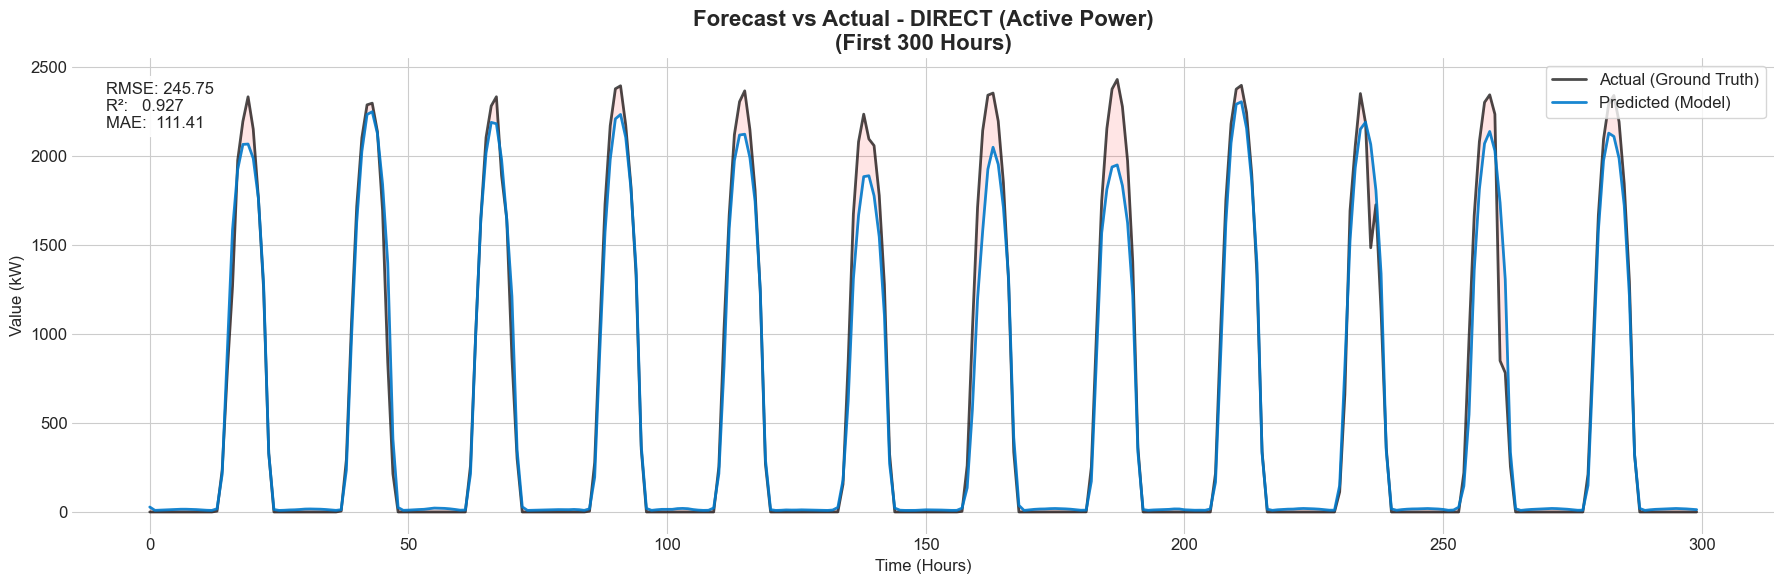

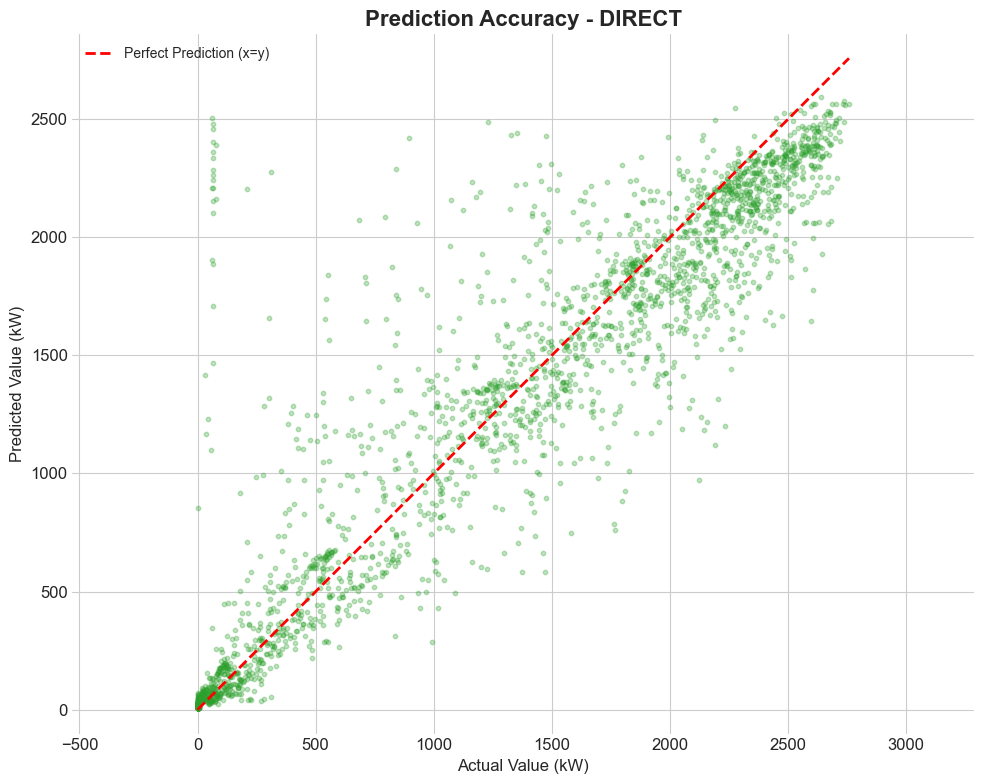


📊 Generating plots for: INDIRECT Mode


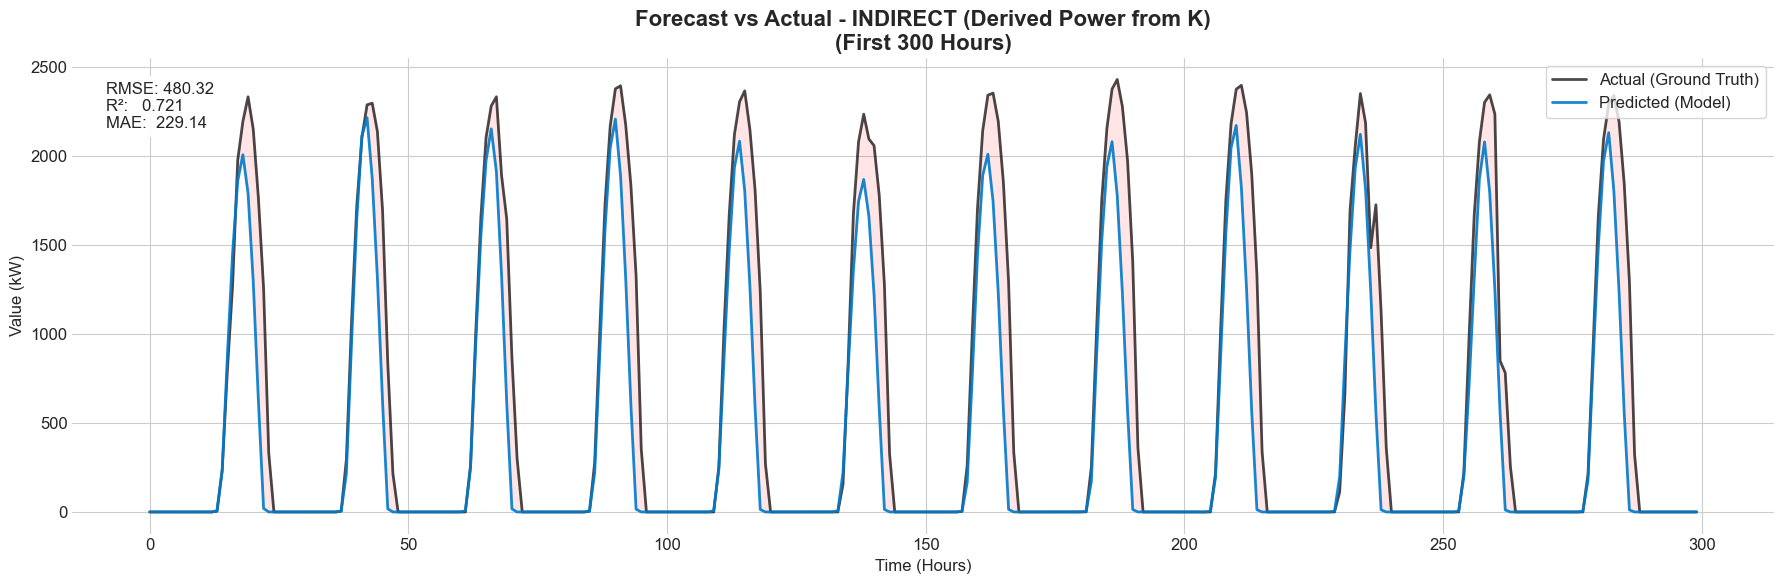

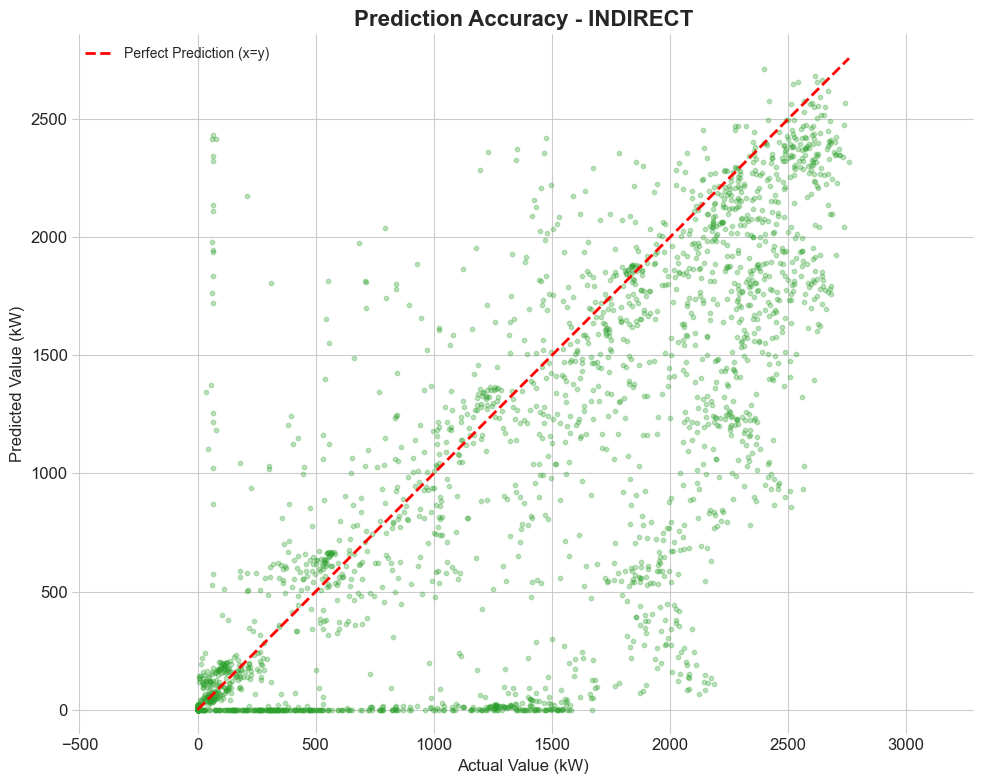


✅ ALL VISUALIZATIONS COMPLETE


In [17]:
# ==============================================================================
# CELL 14: Final Visualizations (Actual vs Predicted)
# ==============================================================================
# Purpose: Generate high-quality plots to visualize model performance.
#          1. Time Series Zoom (First 5 days)
#          2. Scatter Plot (Accuracy)
#          3. Error Distribution
# ==============================================================================

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

print("\n" + "=" * 80)
print("VISUALIZING PREDICTION RESULTS")
print("=" * 80)

# Apply style
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (15, 6)
plt.rcParams['font.size'] = 12

# Check if we have results to plot
if 'evaluation_results' not in globals() or not evaluation_results:
    raise ValueError("❌ No results found! Please run Cell 13 first.")

for mode, results in evaluation_results.items():
    print(f"\n📊 Generating plots for: {mode.upper()} Mode")
    
    # Extract data
    if mode == 'indirect' and 'y_pred_power' in results:
        # For indirect, we prefer to show the converted Power (kW) if available
        y_true = results['y_true_power']
        y_pred = results['y_pred_power']
        title_suffix = "(Derived Power from K)"
        unit = "kW"
        metrics = results['metrics_power']
    elif mode == 'indirect':
        # Fallback to K-Index
        y_true = results['y_true_k']
        y_pred = results['y_pred_k']
        title_suffix = "(K Index)"
        unit = "K"
        metrics = results['metrics_k']
    else:
        # Direct mode
        y_true = results['y_true']
        y_pred = results['y_pred']
        title_suffix = "(Active Power)"
        unit = "kW"
        metrics = results['metrics']

    # --- PLOT 1: Time Series (First 300 hours / ~12 days) ---
    plt.figure(figsize=(18, 6))
    
    # Zoom in on the first 300 samples for clarity
    limit = 300
    if len(y_true) < limit: limit = len(y_true)
    
    plt.plot(y_true[:limit], label='Actual (Ground Truth)', color='black', alpha=0.7, linewidth=2)
    plt.plot(y_pred[:limit], label='Predicted (Model)', color='#007acc', alpha=0.9, linewidth=2)
    
    # Styling
    plt.title(f'Forecast vs Actual - {mode.upper()} {title_suffix}\n(First {limit} Hours)', fontsize=16, fontweight='bold')
    plt.xlabel('Time (Hours)', fontsize=12)
    plt.ylabel(f'Value ({unit})', fontsize=12)
    plt.legend(loc='upper right', frameon=True, fontsize=12)
    plt.fill_between(range(limit), y_true[:limit], y_pred[:limit], color='red', alpha=0.1, label='Error Area')
    
    # Add metrics box
    textstr = '\n'.join((
        f'RMSE: {metrics["rmse"]:.2f}',
        f'R²:   {metrics["r2"]:.3f}',
        f'MAE:  {metrics["mae"]:.2f}'))
    props = dict(boxstyle='round', facecolor='white', alpha=0.9)
    plt.gca().text(0.02, 0.95, textstr, transform=plt.gca().transAxes, fontsize=12,
            verticalalignment='top', bbox=props)
    
    plt.tight_layout()
    plt.show()

    # --- PLOT 2: Scatter Plot (Accuracy) ---
    plt.figure(figsize=(10, 8))
    
    # Downsample for scatter plot if too many points (to keep it fast)
    if len(y_true) > 5000:
        indices = np.random.choice(len(y_true), 5000, replace=False)
        s_true, s_pred = y_true[indices], y_pred[indices]
    else:
        s_true, s_pred = y_true, y_pred
        
    plt.scatter(s_true, s_pred, alpha=0.3, color='#2ca02c', s=10)
    
    # Perfect prediction line
    min_val = min(s_true.min(), s_pred.min())
    max_val = max(s_true.max(), s_pred.max())
    plt.plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2, label='Perfect Prediction (x=y)')
    
    plt.title(f'Prediction Accuracy - {mode.upper()}', fontsize=16, fontweight='bold')
    plt.xlabel(f'Actual Value ({unit})', fontsize=12)
    plt.ylabel(f'Predicted Value ({unit})', fontsize=12)
    plt.legend()
    plt.axis('equal')
    
    plt.tight_layout()
    plt.show()

print("\n" + "=" * 80)
print("✅ ALL VISUALIZATIONS COMPLETE")
print("=" * 80)